# HW1 — Statistical inference and supervised learning

**EE-411 — Fundamentals of Inference and Learning, 2026–2027**

**Learning objectives**
- Derive and compare estimators, quantify uncertainty, and interpret their limits.
- Fit and compare classifiers using cross-validation and a final test set.
- Diagnose class imbalance and apply resampling without leaking validation data.

**Prerequisites:** probability densities, likelihood, basic Bayesian inference, Fisher
information, classification, and Python/NumPy. Required packages are listed in
`requirements.txt`. Open this notebook with `HW1/` as the working directory.

**Working period:** approximately three weeks. The two parts are independent;
plan time for both mathematical reasoning and numerical experiments.

Submit your completed exercise notebook on Moodle by the announced deadline.
Each student submits their own work. AI tools may be used, but you are responsible
for checking and explaining every result. Briefly document how you used them.
Questions marked **optional** are extensions; the remaining questions form the core.

Put mathematical and written answers in the answer slots (you may use
`display(Markdown(r"..."))`), together with the requested code. Explain results;
tables or scores without interpretation are not complete answers. Run your
notebook from a fresh kernel before submitting it.

Use the supplied data; you do not need to download images or run the generators.
We use a fixed random seed (`SEED`) so that random operations give reproducible
results across runs. Setting `random_state=SEED` uses this fixed seed. A seed fixes
one realization, not a universal estimator or classifier ranking.

In [1]:
# PROVIDED: common imports and reproducibility settings.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 2203
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})

## Part I — Statistical inference and estimation

Alex encodes the first two and last two digits of a phone code as parameters
$a$ and $b$. For $0<a<b$, consider the triangular density

$$p(x;a,b)=H(a,b)\begin{cases}
x/a,&0\leq x\leq a,\\
(b-x)/(b-a),&a<x\leq b,\\
0,&\text{otherwise}.
\end{cases}$$

We first treat the parameters as continuous. At the end, discuss the additional
constraint that a code consists of integer pairs. The files in this part reproduce
the current 2026 HW1 data. Do not inspect `generator.py` to obtain the answers.

### Question 1 — Normalization and expectation

Find $H(a,b)$ and derive the mean $\mu=\mathbb E[X]$. Show the integrals.

In [2]:
# TODO: answer Question 1, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
The integral of the probaility density fucntion must be 1 so 

$$H(a,b)\cdot\left(\int_0^a \frac{x}{a} dx + \int_a^b \frac{b-x}{b-a}dx\right) = 1$$

$$H(a,b)\cdot\left(\left[\frac{x^2}{2a}\right]_0^a + \left[\frac{bx}{b-a}\right]_a^b + \left[\frac{-x^2}{2(b-a)}\right]_a^b\right)
=H(a,b)\left(\frac{a}{2}+\frac{b(b-a)}{b-a}+\frac{a^2-b^2}{2(b-a)}\right)$$

$$=H(a,b)\left(\frac{a}{2}+b-\frac{a+b}{2}\right)=H(a,b)\left(\frac{a}{2}+b-\frac{a}{2}-\frac{b}{2}\right)=H(a,b)\frac{b}{2}=1$$
$$\Rightarrow H(a,b) = \frac{2}{b}$$

I am now going to compute $\mu = \mathbb E[X] = \int_{-\infty}^{\infty}x\cdot p(x)$

$$\mu = \frac{2}{b}\cdot\left(\int_0^a \frac{x^2}{a} dx + \int_a^b \frac{bx-x^2}{b-a}dx\right)
=\frac{2}{b}\cdot\left(\left[\frac{x^3}{3a}\right]_0^a + \frac{1}{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b\right)$$
$$=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\left(\frac{b^3-ba^2}{2}-\frac{b^3-a^3}{3}\right)\right)=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\frac{b^3-3ba^2+2a^3}{6}\right)$$
$$=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\frac{(b-a)^2(b+2a)}{6}\right)=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{(b-a)(b+2a)}{6}\right)$$
$$=\frac{2}{b}\cdot\frac{2a^2+b^2+2ab-ab-2a^2}{6}=\frac{1}{b}\cdot\frac{b(b+a)}{3}=\frac{a+b}{3}$$

To sum up we have $H(a,b) = \frac{2}{b}$ and $\mu = \frac{a+b}{3}$
"""))


The integral of the probaility density fucntion must be 1 so 

$$H(a,b)\cdot\left(\int_0^a \frac{x}{a} dx + \int_a^b \frac{b-x}{b-a}dx\right) = 1$$

$$H(a,b)\cdot\left(\left[\frac{x^2}{2a}\right]_0^a + \left[\frac{bx}{b-a}\right]_a^b + \left[\frac{-x^2}{2(b-a)}\right]_a^b\right)
=H(a,b)\left(\frac{a}{2}+\frac{b(b-a)}{b-a}+\frac{a^2-b^2}{2(b-a)}\right)$$

$$=H(a,b)\left(\frac{a}{2}+b-\frac{a+b}{2}\right)=H(a,b)\left(\frac{a}{2}+b-\frac{a}{2}-\frac{b}{2}\right)=H(a,b)\frac{b}{2}=1$$
$$\Rightarrow H(a,b) = \frac{2}{b}$$

I am now going to compute $\mu = \mathbb E[X] = \int_{-\infty}^{\infty}x\cdot p(x)$

$$\mu = \frac{2}{b}\cdot\left(\int_0^a \frac{x^2}{a} dx + \int_a^b \frac{bx-x^2}{b-a}dx\right)
=\frac{2}{b}\cdot\left(\left[\frac{x^3}{3a}\right]_0^a + \frac{1}{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b\right)$$
$$=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\left(\frac{b^3-ba^2}{2}-\frac{b^3-a^3}{3}\right)\right)=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\frac{b^3-3ba^2+2a^3}{6}\right)$$
$$=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{1}{b-a}\frac{(b-a)^2(b+2a)}{6}\right)=\frac{2}{b}\cdot\left(\frac{a^2}{3} + \frac{(b-a)(b+2a)}{6}\right)$$
$$=\frac{2}{b}\cdot\frac{2a^2+b^2+2ab-ab-2a^2}{6}=\frac{1}{b}\cdot\frac{b(b+a)}{3}=\frac{a+b}{3}$$

To sum up we have $H(a,b) = \frac{2}{b}$ and $\mu = \frac{a+b}{3}$


### Question 2 — CDF, median, and mode

Derive the cumulative distribution function $F(t)=\Pr(X\leq t)$ and the median
$m$. Distinguish the cases $a\leq b/2$ and $a>b/2$. Compare the mean, median,
and mode, including the symmetric case.

In [3]:
# TODO: answer Question 2, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
display(Markdown(r"""
Case 1 $\rightarrow t \in [0, a]$ :
$$F_1(t)=\Pr(X\leq t)=\frac{2}{b}\int_0^t\frac{x}{a}dx = \frac{t^2}{ab}$$

Case 2 $\rightarrow t \in [a, b]$ :
$$F_2(t)=\Pr(X\leq t) = 1- \Pr(X> t) = 1- \frac{2}{b}\int_t^b \frac{b-x}{b-a}dx
=1- \frac{2}{b}\left[ \frac{bx-x^2/2}{b-a}\right]_t^b=1- \frac{2}{b}\left(\frac{(b^2-b^2/2)-(bt - t^2/2)}{b-a}\right)$$
$$=1- \frac{b^2-2bt + t^2}{b(b-a)} = 1-\frac{(b-t)^2}{b(b-a)}$$

We have
$$F(t) =\begin{cases}
0, & t < 0\\
F_1(t) = \frac{t^2}{ab},& t \in [0, a] \\
F_2(t) = 1-\frac{(b-t)^2}{b(b-a)},& t \in [a, b]\\
1, & t > b
\end{cases}$$

We see that $F(0) = 0$ and $F(b)=1$ which is what we expect from a cumulative distribution functions

For the median we see that $F(a) = a/b$ so the median is in $F_1$ if $\frac{a}{b}\geq 0.5$ else it's in $F_2$. We solve for both cases.

If $\frac{a}{b}\geq 0.5 \rightarrow \frac{t^2}{ab}=0.5 \rightarrow m = \sqrt{ab/2}$

Else $1-\frac{(b-m)^2}{b(b-a)} = 0.5 \rightarrow (b-m)^2 = \frac{b(b-a)}{2} \rightarrow m = b-\sqrt{\frac{b(b-a)}{2}}$

So we have 
$$m =\begin{cases}
\sqrt{ab/2},& \text{if } \frac{a}{b}\geq 0.5 \\
b-\sqrt{\frac{b(b-a)}{2}},& \text{if } \frac{a}{b} < 0.5
\end{cases}$$


By exploring the different cases we can fill the table bellow as summary.

| x      | Left-skewed ($a>b/2$) | Symmetric ($a=b/2$) | Right-skewed ($a<b/2$) |
|--------|-----------------------|---------------------|------------------------|
| mode   | $a$ | $a = b/2$ | $a$ | 
| median | $m = \sqrt{ab/2}$ | $m = b/2$ | $m = b-\sqrt{\frac{b(b-a)}{2}}$ |
| mean   | $\mu = \frac{a+b}{3}$ | $\mu = b/2$ | $\mu = \frac{a+b}{3}$ |
| comments   | $\mu < m < \text{mode}$ | $\mu = m = \text{mode}$ | $\text{mode} < m < \mu$ |
"""))


Case 1 $\rightarrow t \in [0, a]$ :
$$F_1(t)=\Pr(X\leq t)=\frac{2}{b}\int_0^t\frac{x}{a}dx = \frac{t^2}{ab}$$

Case 2 $\rightarrow t \in [a, b]$ :
$$F_2(t)=\Pr(X\leq t) = 1- \Pr(X> t) = 1- \frac{2}{b}\int_t^b \frac{b-x}{b-a}dx
=1- \frac{2}{b}\left[ \frac{bx-x^2/2}{b-a}\right]_t^b=1- \frac{2}{b}\left(\frac{(b^2-b^2/2)-(bt - t^2/2)}{b-a}\right)$$
$$=1- \frac{b^2-2bt + t^2}{b(b-a)} = 1-\frac{(b-t)^2}{b(b-a)}$$

We have
$$F(t) =\begin{cases}
0, & t < 0\\
F_1(t) = \frac{t^2}{ab},& t \in [0, a] \\
F_2(t) = 1-\frac{(b-t)^2}{b(b-a)},& t \in [a, b]\\
1, & t > b
\end{cases}$$

We see that $F(0) = 0$ and $F(b)=1$ which is what we expect from a cumulative distribution functions

For the median we see that $F(a) = a/b$ so the median is in $F_1$ if $\frac{a}{b}\geq 0.5$ else it's in $F_2$. We solve for both cases.

If $\frac{a}{b}\geq 0.5 \rightarrow \frac{t^2}{ab}=0.5 \rightarrow m = \sqrt{ab/2}$

Else $1-\frac{(b-m)^2}{b(b-a)} = 0.5 \rightarrow (b-m)^2 = \frac{b(b-a)}{2} \rightarrow m = b-\sqrt{\frac{b(b-a)}{2}}$

So we have 
$$m =\begin{cases}
\sqrt{ab/2},& \text{if } \frac{a}{b}\geq 0.5 \\
b-\sqrt{\frac{b(b-a)}{2}},& \text{if } \frac{a}{b} < 0.5
\end{cases}$$


By exploring the different cases we can fill the table bellow as summary.

| x      | Left-skewed ($a>b/2$) | Symmetric ($a=b/2$) | Right-skewed ($a<b/2$) |
|--------|-----------------------|---------------------|------------------------|
| mode   | $a$ | $a = b/2$ | $a$ | 
| median | $m = \sqrt{ab/2}$ | $m = b/2$ | $m = b-\sqrt{\frac{b(b-a)}{2}}$ |
| mean   | $\mu = \frac{a+b}{3}$ | $\mu = b/2$ | $\mu = \frac{a+b}{3}$ |
| comments   | $\mu < m < \text{mode}$ | $\mu = m = \text{mode}$ | $\text{mode} < m < \mu$ |


### Question 3 — Implement the density and inspect the sample

For the file `fixed_b.npy`, $b=20$ is known. Implement `pdf(x, a, b=20)`.
Load the data, report its size, empirical mean and median, and plot a density
histogram with a density curve for an admissible $a$ of your choice.
Label the figure. Do not assume that your chosen plotting value is the true $a$.

Loaded data with shape (100,), median 10.70, empirical mean 10.74



We see that our function behave as expected (triangular pdf with area of 1, equals to 0 outside [0, b]). The parameter 'a' is set to 5 as an example for plotting but wasn't fitted to the data.


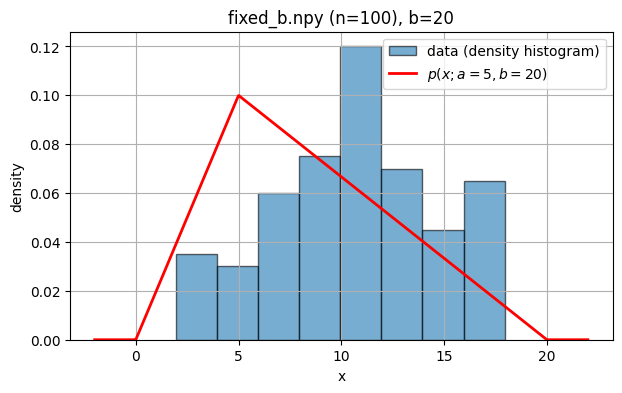

In [4]:
# TODO: answer Question 3, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

def pdf(x, a, b=20):

    H = 2.0 / b
    left = x / a
    right = (b - x) / (b - a)

    pdf = H * np.where(
                        (x >= 0) & (x <= a), left, 
                        np.where((x > a) & (x <= b), right, 0.0))
    return pdf


data_fixed_b = np.load("fixed_b.npy")

print(f"Loaded data with shape {data_fixed_b.shape}, median {np.median(data_fixed_b):.2f}, empirical mean {np.mean(data_fixed_b):.2f}")

b = 20
A_example = 5
n = data_fixed_b.size

fig, ax = plt.subplots()
ax.hist(data_fixed_b, bins="auto", density=True, alpha=0.6, edgecolor="k",
        label="data (density histogram)")
grid = np.linspace(-2, b+2, 1000)
ax.plot(grid, pdf(grid, A_example, b), "r-", lw=2,
        label=rf"$p(x;a={A_example},b={b})$")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title(f"fixed_b.npy (n={n}), b={b}")
ax.legend()

display(Markdown(r"""
We see that our function behave as expected (triangular pdf with area of 1, equals to 0 outside [0, b]). The parameter 'a' is set to 5 as an example for plotting but wasn't fitted to the data.
"""))

### Question 4 — Mean and median estimators

Invert the expressions for the population mean and median to derive
$\hat a_{\mathrm{mean}}$ and $\hat a_{\mathrm{median}}$. Implement them and
evaluate them on the sample. Can finite-sample estimates fall outside $(0,b)$?
Use the untruncated formulas in the later MSE comparison and explain this choice.

In [5]:
# TODO: answer Question 4, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
From $Q1$ we have $\mu = \frac{a+b}{3}$. We empirically estimates $\mu = \bar{x}$ and find $\hat a_{\mathrm{mean}} = 3\bar{x}-b$

From $Q2$ we have $m =\begin{cases}
\sqrt{ab/2},& \text{if } \frac{a}{b}\geq 0.5 \\
b-\sqrt{\frac{b(b-a)}{2}},& \text{if } \frac{a}{b} < 0.5
\end{cases}$. 
So we estimates $\hat m$ from our data and get the following by reversing the formulas
$$\hat a_{\mathrm{median}} =\begin{cases}
2\hat{m}^2/b,& \text{if } \hat{m}\geq b/2 \\
b-\frac{2(b-\hat{m})^2}{b},& \text{if } \hat{m} < b/2
\end{cases}$$

Can finite-sample estimates fall outside $(0,b)$? $\rightarrow$ Yes the formula doesn't know that $a$ must lie in $(0,b)$. We see that for the mean if $\bar{x} < b/3$ then $\hat a_{\mathrm{mean}} <0$. It could happen if most of the data are on the left side of the distribution, if that's the case, we should try to find a better window. That's why when applying a formula to a sample we must be careful as we could have noise, bad parameters selection, unexpected behaviour, etc.

If we truncate the estimators to $(0,b)$ we'll artificially reduce the MSE and improve our confidence in the estimator which is dangerous as it could be wrong and too optimistic about the result. It also bias the estimator so the unbiased Cramér–Rao bound cannot be used to compare anymore. That's why we'll use the untruncated formula.
"""))

def estimate_a_mean(mu, b):
    return 3.0 * mu - b

def estimate_a_median(m, b):
    if m >= b / 2:
        return 2.0 * m**2 / b
    return b - 2.0 * (b - m) ** 2 / b

def in_range(a_hat, b):
    return 0 < a_hat < b

a_hat_mean = estimate_a_mean(np.mean(data_fixed_b), b=b)
a_hat_median = estimate_a_median(np.median(data_fixed_b), b=b)

print(f"a_hat_mean = {a_hat_mean:.4f} in (0,b): {in_range(a_hat_mean, b)}")
print(f"a_hat_median = {a_hat_median:.4f} in (0,b): {in_range(a_hat_median, b)}")


From $Q1$ we have $\mu = \frac{a+b}{3}$. We empirically estimates $\mu = \bar{x}$ and find $\hat a_{\mathrm{mean}} = 3\bar{x}-b$

From $Q2$ we have $m =\begin{cases}
\sqrt{ab/2},& \text{if } \frac{a}{b}\geq 0.5 \\
b-\sqrt{\frac{b(b-a)}{2}},& \text{if } \frac{a}{b} < 0.5
\end{cases}$. 
So we estimates $\hat m$ from our data and get the following by reversing the formulas
$$\hat a_{\mathrm{median}} =\begin{cases}
2\hat{m}^2/b,& \text{if } \hat{m}\geq b/2 \\
b-\frac{2(b-\hat{m})^2}{b},& \text{if } \hat{m} < b/2
\end{cases}$$

Can finite-sample estimates fall outside $(0,b)$? $\rightarrow$ Yes the formula doesn't know that $a$ must lie in $(0,b)$. We see that for the mean if $\bar{x} < b/3$ then $\hat a_{\mathrm{mean}} <0$. It could happen if most of the data are on the left side of the distribution, if that's the case, we should try to find a better window. That's why when applying a formula to a sample we must be careful as we could have noise, bad parameters selection, unexpected behaviour, etc.

If we truncate the estimators to $(0,b)$ we'll artificially reduce the MSE and improve our confidence in the estimator which is dangerous as it could be wrong and too optimistic about the result. It also bias the estimator so the unbiased Cramér–Rao bound cannot be used to compare anymore. That's why we'll use the untruncated formula.


a_hat_mean = 12.2193 in (0,b): True
a_hat_median = 11.4501 in (0,b): True


### Question 5 — Likelihood and maximum likelihood

Write and plot the log-likelihood $\ell(a;x_1,\ldots,x_n)$ for known $b=20$.
Compute the maximum-likelihood estimate. Check the maximum over a grid or the
sample locations rather than trusting a single local optimizer.

For numerical endpoint handling, optimize over $[\varepsilon b,(1-\varepsilon)b]$
with $\varepsilon=10^{-8}$. Report if the solution reaches a numerical boundary.
Explain why the log-likelihood can have several local maxima.


$$\ell(a; X) = \sum_{i=1}^n log\space p(x_i; a, b)$$
We split the sum depending on the position of $x_i$ and we call $k$ the number of sample $\leq a \rightarrow k(a)=\#\{i: x_i\le a\}$. So we have $(n-k)$ samples $>a$
$$\ell(a; X) = n\cdot log\left(\frac{2}{b}\right) + \sum_{x_i \leq a} (log (x_i) - log (a)) + \sum_{x_i > a} (log (b-x_i) - log (b-a))$$
$$= n\cdot log\left(\frac{2}{b}\right) + \sum_{x_i \leq a} log (x_i)  + \sum_{x_i > a} log (b-x_i) - k\space log (a) - (n-k)log (b-a)$$

For $a$ between two consecutive samples, $k$ stays the same so the $\ell(a;X)$ becomes $C-k\space log (a) - (n-k)log (b-a)$, where C is a constant. We easily see that this function is convex (sum of $-log$ which is convex) and therefore cannot have an interior maximum. However, $\ell$ is only piecewise smooth as it is continuous, but its derivative jumps at each data point $x_i$. Each data point is a concave "kink" and can be a local maximum, so there can be several of them. That is why these points must be evaluated explicitly. 

To find the MLE we'll have to evaluate $\ell$ on the the following values sample points, a fine grid (shouldn't be here but we still check), the two endpoints, and take the maximum.


number of local maxima: 1
Maximum Likelihood Estimate (MLE) for a: 11.365795979104222
Solution reached numerical boundary: No


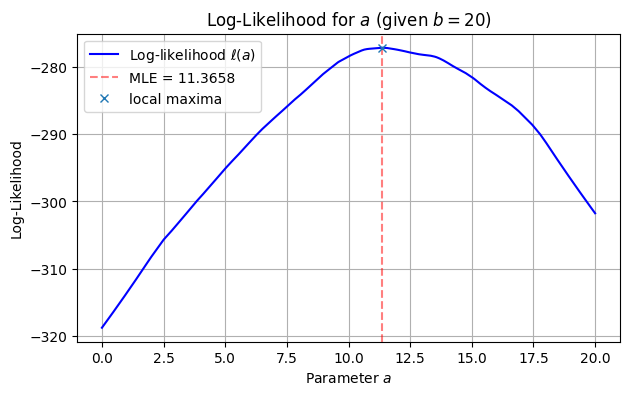


In our case we only have one local maxima and it's therefore the best candidate for the maximum-likelihood estimator. We observed that its value of $11.36$ is close to the ones of $\hat a_{\mathrm{median}}(=11.45)$ and $\hat a_{\mathrm{mean}} (=12.22)$ we found before.


In [6]:
# TODO: answer Question 5, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
$$\ell(a; X) = \sum_{i=1}^n log\space p(x_i; a, b)$$
We split the sum depending on the position of $x_i$ and we call $k$ the number of sample $\leq a \rightarrow k(a)=\#\{i: x_i\le a\}$. So we have $(n-k)$ samples $>a$
$$\ell(a; X) = n\cdot log\left(\frac{2}{b}\right) + \sum_{x_i \leq a} (log (x_i) - log (a)) + \sum_{x_i > a} (log (b-x_i) - log (b-a))$$
$$= n\cdot log\left(\frac{2}{b}\right) + \sum_{x_i \leq a} log (x_i)  + \sum_{x_i > a} log (b-x_i) - k\space log (a) - (n-k)log (b-a)$$

For $a$ between two consecutive samples, $k$ stays the same so the $\ell(a;X)$ becomes $C-k\space log (a) - (n-k)log (b-a)$, where C is a constant. We easily see that this function is convex (sum of $-log$ which is convex) and therefore cannot have an interior maximum. However, $\ell$ is only piecewise smooth as it is continuous, but its derivative jumps at each data point $x_i$. Each data point is a concave "kink" and can be a local maximum, so there can be several of them. That is why these points must be evaluated explicitly. 

To find the MLE we'll have to evaluate $\ell$ on the the following values sample points, a fine grid (shouldn't be here but we still check), the two endpoints, and take the maximum.
"""))

epsilon = 1e-8
a_min, a_max = epsilon * b, (1 - epsilon) * b

# Grid points and samples
x_sorted = np.sort(data_fixed_b)

grid_a = np.linspace(a_min, a_max, 1000)
valid_samples = x_sorted[(x_sorted >= a_min) & (x_sorted <= a_max)]
test_a = np.unique(np.concatenate([grid_a, valid_samples]))
test_a = np.sort(test_a)

# log-likelihood
def loglik(a, sample):
    a = np.atleast_1d(a)[None, :]
    X = sample[:, None]
    
    t1 = np.where(X <= a, np.log(X) - np.log(a), 0.0)
    t2 = np.where(X > a, np.log(b - X) - np.log(b - a), 0.0)
    
    return len(sample) * np.log(2/b) + np.sum(t1 + t2, axis=0)

loglike = loglik(test_a, x_sorted)

# MLE
max_idx = np.argmax(loglike)
a_mle = test_a[max_idx]
hit_boundary = np.isclose(a_mle, a_min) or np.isclose(a_mle, a_max)

j = np.arange(1, n + 1)
left  = -(j - 1)/x_sorted + (n - j + 1)/(b - x_sorted)
right = -j/x_sorted       + (n - j)/(b - x_sorted)
local_max = x_sorted[(left > 0) & (right < 0)]

print("number of local maxima:", local_max.size)
print(f"Maximum Likelihood Estimate (MLE) for a: {a_mle}")
print(f"Solution reached numerical boundary: {'Yes' if hit_boundary else 'No'}")

plt.figure()
plt.plot(test_a, loglike, label=r'Log-likelihood $\ell(a)$', color='blue')
plt.axvline(a_mle, color='red', linestyle='--', label=f'MLE = {a_mle:.4f}', alpha=0.5)
plt.plot(local_max, loglik(local_max, x_sorted), "x", label="local maxima")
plt.title(f'Log-Likelihood for $a$ (given $b={b}$)')
plt.xlabel('Parameter $a$')
plt.ylabel('Log-Likelihood')
plt.legend()
plt.show()

display(Markdown(r"""
In our case we only have one local maxima and it's therefore the best candidate for the maximum-likelihood estimator. We observed that its value of $11.36$ is close to the ones of $\hat a_{\mathrm{median}}(=11.45)$ and $\hat a_{\mathrm{mean}} (=12.22)$ we found before.
"""))

### Question 6 — Bootstrap uncertainty

Use 1,000 nonparametric bootstrap samples of size $n$ to compute percentile 95%
confidence intervals for the mean, median, and maximum-likelihood estimators.
Use the same bootstrap samples for the three estimators. Report the point estimates
and intervals. Explain the frequentist interpretation and whether a unique
integer value of $a$ is established.

In [7]:
# TODO: answer Question 6, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

n_boot = 1000

boot_mean = np.zeros(n_boot)
boot_median = np.zeros(n_boot)
boot_mle = np.zeros(n_boot)

rng = np.random.default_rng(SEED)

for i in range(n_boot):
    # Draw one bootstrap sample and use it for all three estimators
    boot_sample = np.sort(rng.choice(x_sorted, size=n, replace=True))

    boot_mean[i] = estimate_a_mean(np.mean(boot_sample), b)
    boot_median[i] = estimate_a_median(np.median(boot_sample), b)
    
    valid_boot = boot_sample[(boot_sample >= epsilon * b) & (boot_sample <= (1 - epsilon) * b)]
    test_a_boot = np.sort(np.unique(np.concatenate([grid_a, valid_boot])))
    boot_mle[i] = test_a_boot[np.argmax(loglik(test_a_boot, boot_sample))]
    
intervals = {
    "Mean": (a_hat_mean, np.percentile(boot_mean, [2.5, 97.5])),
    "Median": (a_hat_median, np.percentile(boot_median, [2.5, 97.5])),
    "MLE": (a_mle, np.percentile(boot_mle, [2.5, 97.5]))
}

print("95% Percentile Confidence Intervals:")
for estimator, (point_estimate, ci) in intervals.items():
    print(f"{estimator}: point estimate = {point_estimate:.4f}, 95% CI = [{ci[0]:.4f}, {ci[1]:.4f}])")

display(Markdown(r"""
The three point estimates all are inside each other’s intervals, so the estimators agree within sampling noise. The natural numbers inside all three intervals are $10$, $11$, $12$ and $13$ (MLE and Mean also have $14$). So we cannot conclude with enough statistical certainty to a unique integer with a $95\%$ confidence interval.

It is important to keep in mind that in reality the true number is fixed and is $100\%$ of the time the same. The probabilty we computed comes from the observations. And it is still possible that if we are (really) unlucky the true number still lies outside of this 4 integers.
"""))

95% Percentile Confidence Intervals:
Mean: point estimate = 12.2193, 95% CI = [9.9446, 14.6112])
Median: point estimate = 11.4501, 95% CI = [9.9208, 13.2825])
MLE: point estimate = 11.3658, 95% CI = [9.8570, 14.7305])



The three point estimates all are inside each other’s intervals, so the estimators agree within sampling noise. The natural numbers inside all three intervals are $10$, $11$, $12$ and $13$ (MLE and Mean also have $14$). So we cannot conclude with enough statistical certainty to a unique integer with a $95\%$ confidence interval.

It is important to keep in mind that in reality the true number is fixed and is $100\%$ of the time the same. The probabilty we computed comes from the observations. And it is still possible that if we are (really) unlucky the true number still lies outside of this 4 integers.


### Question 7 — Fisher information and the Cramér–Rao bound

Compute the one-observation Fisher information
$I_1(a)=\mathbb E[(\partial_a\log p(X;a,b))^2]$ for fixed $b$ and interior $a$.
Deduce $I_n(a)$ and the Cramér–Rao variance bound for an unbiased estimator.
Which of the estimators above is known to be unbiased? Explain why the unbiased
bound must not be asserted as a finite-sample MSE bound for every estimator.

In [8]:
# TODO: answer Question 7, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
For one single observation ($n=1$), the log-likelihood becomes

$$log\space p(x;a,b) = \begin{cases}
log(2/b)+log(x)-log(a), &0\leq x \leq a\\
log(2/b)+log(b-x)-log(b-a), &a\leq x \leq b\\
\end{cases}$$
And the partial derivative is
$$\partial_a \space log\space p(x;a,b) = \begin{cases}
-\frac{1}{a}, & x < a\\
\text{undefined}, & x = a \\
\frac{1}{b-a}, & x > a\\
\end{cases}$$

The Fisher informtaion can now be computed 
$$I_1(a) = \mathbb E[(\partial_a\log p(X;a,b))^2] = \int_0^a \left(-\frac{1}{a}\right)^2 p(x;a,b)dx + \int_a^b\left(\frac{1}{b-a}\right)^2p(x;a,b)dx
= \int_0^a \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{x}{a}dx + \int_a^b\left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{b-x}{b-a}dx$$
$$= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\int_0^a\frac{x}{a}dx + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\int_a^b(b-x)dx
= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{a}{2} + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\left(\frac{b^2}{2} - ab + \frac{a^2}{2}\right)$$
$$= \frac{1}{a^2} \frac{a}{b} + \frac{1}{(b-a)^3}\frac{1}{b}\left(b^2 - 2ab + a^2\right) 
= \frac{1}{ab} + \frac{1}{b(b-a)} 
= \frac{b-a+a}{ab(b-a)} 
= \frac{1}{a(b-a)}$$

We know from the course that for a sample of $n$ independent and identically distributed observations, the Fisher information is additive $\rightarrow I_n(a) = n \cdot I_1(a) = \frac{n}{a(b-a)}$.

Now the Craméro-Rao bound says that $Var(\hat{a})\geq I_n(a)^{-1} = \frac{a(b-a)}{n}$

The mean estimator $\hat a_{\mathrm{mean}}$ is the only one to be unbiased. 
$$Bias(\hat a_{\mathrm{mean}}) = \mathbb E[\hat a_{\mathrm{mean}}] - a = \mathbb E [3\bar{X}-b] -a =3\mathbb E[\bar{X}]-b -a = 3 \left(\frac{a+b}{3}\right)-b-a = 0$$

For any estimator, $\text{MSE} = \text{Variance} + \text{Bias}^2$. The bound only limits the variance for estimators with zero bias. Now if we imagine an estimator with a big bias and a small variance for example a constant estimator that always tell $a = 12$, if by luck the right number was 12 we would have a zero variance as well as a zero MSE and that would beat any bound. 
"""))


For one single observation ($n=1$), the log-likelihood becomes

$$log\space p(x;a,b) = \begin{cases}
log(2/b)+log(x)-log(a), &0\leq x \leq a\\
log(2/b)+log(b-x)-log(b-a), &a\leq x \leq b\\
\end{cases}$$
And the partial derivative is
$$\partial_a \space log\space p(x;a,b) = \begin{cases}
-\frac{1}{a}, & x < a\\
\text{undefined}, & x = a \\
\frac{1}{b-a}, & x > a\\
\end{cases}$$

The Fisher informtaion can now be computed 
$$I_1(a) = \mathbb E[(\partial_a\log p(X;a,b))^2] = \int_0^a \left(-\frac{1}{a}\right)^2 p(x;a,b)dx + \int_a^b\left(\frac{1}{b-a}\right)^2p(x;a,b)dx
= \int_0^a \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{x}{a}dx + \int_a^b\left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{b-x}{b-a}dx$$
$$= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\int_0^a\frac{x}{a}dx + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\int_a^b(b-x)dx
= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{a}{2} + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\left(\frac{b^2}{2} - ab + \frac{a^2}{2}\right)$$
$$= \frac{1}{a^2} \frac{a}{b} + \frac{1}{(b-a)^3}\frac{1}{b}\left(b^2 - 2ab + a^2\right) 
= \frac{1}{ab} + \frac{1}{b(b-a)} 
= \frac{b-a+a}{ab(b-a)} 
= \frac{1}{a(b-a)}$$

We know from the course that for a sample of $n$ independent and identically distributed observations, the Fisher information is additive $\rightarrow I_n(a) = n \cdot I_1(a) = \frac{n}{a(b-a)}$.

Now the Craméro-Rao bound says that $Var(\hat{a})\geq I_n(a)^{-1} = \frac{a(b-a)}{n}$

The mean estimator $\hat a_{\mathrm{mean}}$ is the only one to be unbiased. 
$$Bias(\hat a_{\mathrm{mean}}) = \mathbb E[\hat a_{\mathrm{mean}}] - a = \mathbb E [3\bar{X}-b] -a =3\mathbb E[\bar{X}]-b -a = 3 \left(\frac{a+b}{3}\right)-b-a = 0$$

For any estimator, $\text{MSE} = \text{Variance} + \text{Bias}^2$. The bound only limits the variance for estimators with zero bias. Now if we imagine an estimator with a big bias and a small variance for example a constant estimator that always tell $a = 12$, if by luck the right number was 12 we would have a zero variance as well as a zero MSE and that would beat any bound. 


### Question 8 — Jeffreys prior and posterior estimation

Derive and normalize Jeffreys prior $\pi_J(a)\propto\sqrt{I_1(a)}$ on $(0,b)$.
Inspect the posterior density near the boundaries: does maximizing it define a
finite interior global MAP estimate? Distinguish MAP from maximum likelihood.

Instead, compute the posterior mean and an equal-tailed 95% credible interval
for `fixed_b.npy`. Numerical integration is sufficient. Hint: the substitution
$a=b\sin^2\theta$, $0<\theta<\pi/2$, removes the prior's integrable endpoint
singularities. Compare the interpretation with Question 6. Check numerical
stability by increasing your integration resolution.

In [9]:
# TODO: answer Question 8, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
We replace $I_1$ by the expression we foudn previously. To normalise it over $(0,b)$ we'll have to set the integral to 1.

$$\pi_J(a) \propto \sqrt{\frac{1}{a(b-a)}} \xrightarrow{\text{normalization}}C\int_0^b\sqrt{\frac{1}{a(b-a)}} da = 1$$

Here I need to apply the hint given in the intruction, let's apply the substitution $a=b\sin^2\theta$, $0<\theta<\pi/2$. It gives the differential $da = 2b\sin\theta \cos\theta d\theta$

$$C\int_0^b\sqrt{\frac{1}{a(b-a)}} da = C\int_0^{\pi/2}\frac{1}{\sqrt{b\sin^2\theta(b-b\sin^2\theta)}} 2b\sin\theta\cos\theta d\theta$$
$$= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{\sqrt{b^2\sin^2\theta(1-\sin^2\theta)}} d\theta
= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{\sqrt{b^2\sin^2\theta \cos^2\theta}} d\theta
= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{b\sin\theta \cos\theta} d\theta$$
$$= C\int_0^{\pi/2}2d\theta = 2C \left[\theta\right]_0^{\pi/2} = 2C\left(\frac{\pi}{2}\right) = C\pi$$

Putting it equals to $1$ leads to $C = \pi^{-1}$. And the normalized Jeffreys prios is:
$$\pi_J(a) = \frac{1}{\pi\sqrt{a(b-a)}}$$

The posterior density is proportional to the likelihood times the prior $p(a \vert{} X) \propto L(a; X) \pi_J(a)$. We easily see that at the boundaries ($a\rightarrow 0$ or $a\rightarrow b$) the denominator of the prior will go to zero and the posterior density will go to infinity. Therefore there is no maximum finite interior MAP estimate. If we try to maximize the MAP the posterior would push the estimate to the boundary, which are invalid parameter in our problem. Therefore the posterior has no finite global maximum in that interval.

The MLE is only constructed on the datas (maximizes $\ell(a; X)$), It finds a peak at one of the interior sample points.The MAP estimate maximizes $\ell(a; X)\pi_J(a)$. Here, the infinite asymptotes of the Jeffreys prior heavily dominate the data at the boundaries, destroying the interior peak and pushing the maximum to the edges.
"""))

def bayesian_posterior_inference(x_sorted, b=20, num_theta=10000):
    eps = 1e-8
    theta = np.linspace(eps, np.pi/2 - eps, num_theta)
    
    # theta -> a
    a_grid = b * np.sin(theta)**2
    
    # loglik
    loglike = loglik(a_grid, x_sorted)
    
    loglike_max = np.max(loglike)
    posterior_unnorm = np.exp(loglike - loglike_max) 
    
    # Normalize (Integration over d_theta)
    d_theta = theta[1] - theta[0]
    Z = np.sum(posterior_unnorm) * d_theta
    posterior_pdf = posterior_unnorm / Z
    
    # Posterior Mean
    posterior_mean = np.sum(a_grid * posterior_pdf) * d_theta
    
    # 95% Equal-Tailed Credible Interval
    cdf = np.cumsum(posterior_pdf) * d_theta
    ci_lower = a_grid[np.searchsorted(cdf, 0.025)]
    ci_upper = a_grid[np.searchsorted(cdf, 0.975)]
    
    print(f"Posterior Mean: {posterior_mean:.4f}")
    print(f"95% Credible Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
    
for i in np.linspace(1, 6, 5):
    n_integration_steps = 10 ** int(i)
    print(f"\nFor 10^{int(i)} integration steps")
    bayesian_posterior_inference(x_sorted, b=b, num_theta=n_integration_steps)

display(Markdown(r"""
We see that the interval converge to $[9.74, 13.94]$ as we increase the number of integration step. 

Before ($Q6$ - frequentist approach) the true parameter $a$ was a fixed, unknown constant. The $95\%$ confidence interval was a random variable depending on samples. The $95\%$ means that if you repeated the sampling process a lot of times, $95\%$ of the generated intervals would contain the true fixed parameter.

In this question ($Q8$ - Bayesian approach) the data is fixed and known. The parameter $a$ is treated as a random variable reflecting our updated state of belief. A $95\%$ interval means that there is a $95\%$ probability that the true parameter $a$ lies within this specific calculated interval, given the observed data and the chosen prior
"""))


We replace $I_1$ by the expression we foudn previously. To normalise it over $(0,b)$ we'll have to set the integral to 1.

$$\pi_J(a) \propto \sqrt{\frac{1}{a(b-a)}} \xrightarrow{\text{normalization}}C\int_0^b\sqrt{\frac{1}{a(b-a)}} da = 1$$

Here I need to apply the hint given in the intruction, let's apply the substitution $a=b\sin^2\theta$, $0<\theta<\pi/2$. It gives the differential $da = 2b\sin\theta \cos\theta d\theta$

$$C\int_0^b\sqrt{\frac{1}{a(b-a)}} da = C\int_0^{\pi/2}\frac{1}{\sqrt{b\sin^2\theta(b-b\sin^2\theta)}} 2b\sin\theta\cos\theta d\theta$$
$$= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{\sqrt{b^2\sin^2\theta(1-\sin^2\theta)}} d\theta
= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{\sqrt{b^2\sin^2\theta \cos^2\theta}} d\theta
= C\int_0^{\pi/2}\frac{2b\sin\theta\cos\theta}{b\sin\theta \cos\theta} d\theta$$
$$= C\int_0^{\pi/2}2d\theta = 2C \left[\theta\right]_0^{\pi/2} = 2C\left(\frac{\pi}{2}\right) = C\pi$$

Putting it equals to $1$ leads to $C = \pi^{-1}$. And the normalized Jeffreys prios is:
$$\pi_J(a) = \frac{1}{\pi\sqrt{a(b-a)}}$$

The posterior density is proportional to the likelihood times the prior $p(a \vert{} X) \propto L(a; X) \pi_J(a)$. We easily see that at the boundaries ($a\rightarrow 0$ or $a\rightarrow b$) the denominator of the prior will go to zero and the posterior density will go to infinity. Therefore there is no maximum finite interior MAP estimate. If we try to maximize the MAP the posterior would push the estimate to the boundary, which are invalid parameter in our problem. Therefore the posterior has no finite global maximum in that interval.

The MLE is only constructed on the datas (maximizes $\ell(a; X)$), It finds a peak at one of the interior sample points.The MAP estimate maximizes $\ell(a; X)\pi_J(a)$. Here, the infinite asymptotes of the Jeffreys prior heavily dominate the data at the boundaries, destroying the interior peak and pushing the maximum to the edges.



For 10^1 integration steps
Posterior Mean: 11.7763
95% Credible Interval: [11.7365, 11.7365]

For 10^2 integration steps
Posterior Mean: 11.6496
95% Credible Interval: [9.8413, 13.8635]

For 10^3 integration steps
Posterior Mean: 11.6495
95% Credible Interval: [9.7327, 13.9608]

For 10^4 integration steps
Posterior Mean: 11.6495
95% Credible Interval: [9.7408, 13.9473]

For 10^6 integration steps


/tmp/ipykernel_37355/416322283.py:33: RuntimeWarning: divide by zero encountered in log
  t2 = np.where(X > a, np.log(b - X) - np.log(b - a), 0.0)


Posterior Mean: 11.6495
95% Credible Interval: [9.7409, 13.9477]



We see that the interval converge to $[9.74, 13.94]$ as we increase the number of integration step. 

Before ($Q6$ - frequentist approach) the true parameter $a$ was a fixed, unknown constant. The $95\%$ confidence interval was a random variable depending on samples. The $95\%$ means that if you repeated the sampling process a lot of times, $95\%$ of the generated intervals would contain the true fixed parameter.

In this question ($Q8$ - Bayesian approach) the data is fixed and known. The parameter $a$ is treated as a random variable reflecting our updated state of belief. A $95\%$ interval means that there is a $95\%$ probability that the true parameter $a$ lies within this specific calculated interval, given the observed data and the chosen prior


### Question 9 — Sampling the distribution

Derive an inverse-CDF sampler from Question 2. Implement a vectorized function
`sample_triangular(a, b, size, rng)`, and check its empirical mean and histogram
using 10,000 samples with $a=13,b=20$. Explain why it avoids the repeated rejection
steps of a rejection sampler. Use only interior parameters $0<a<b$.


As a reminder, I found 
$$F(t) =\begin{cases}
0, & t < 0\\
F_1(t) = \frac{t^2}{ab},& t \in [0, a] \\
F_2(t) = 1-\frac{(b-t)^2}{b(b-a)},& t \in [a, b]\\
1, & t > b
\end{cases}$$

We now want to do the opposite, given a probability $y$ what is the $t$ that gives us $F(t) = y$. Using the inverse-transform method we set $y \sim U(0,1)$ so it's a uniform random variable. And we now solve for $t = F^{-1}(y)$. We now that it will peak in $y=a/b$ so we explore the two sides. 

Case 1: $y \leq a/b \rightarrow$ maps to $t\leq a$

$$y = \frac{t^2}{ab} \Rightarrow t^2 = yab \Rightarrow t = \sqrt{yab}$$

Case 2: $y > a/b \rightarrow$ maps to $t > a$

$$y = 1-\frac{(b-t)^2}{b(b-a)} \Rightarrow (b-t)^2 = b(b-a)(1-y)$$

The instruction constraints $t$ to be smaller than $b$, so we can now take the positive root of $(b-t)^2$
$$b-t = \sqrt{b(b-a)(1-y)} \Rightarrow t = b - \sqrt{b(b-a)(1-y)}$$

The inverse-CDF sampler is 
$$F^{-1}(y) =
\begin{cases} 
\sqrt{yab}, & \text{if } y \leq \frac{a}{b} 
\\ b - \sqrt{(1-y)b(b-a)}, & \text{if } y > \frac{a}{b} 
\end{cases}$$


Empirical mean:  11.0105
Theoretical mean: 11.0000


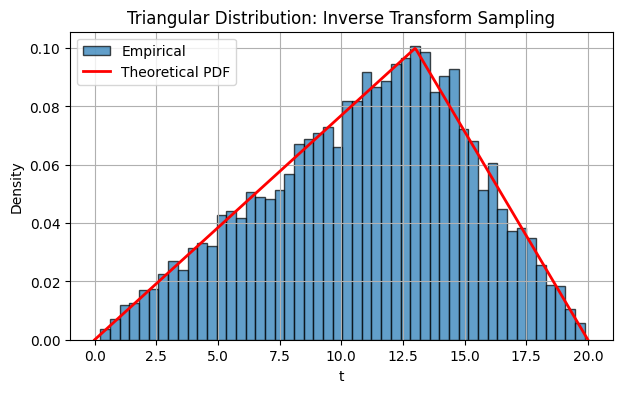


We see that the empircal mean is $11.0105$ and that it's matching the theoretical mean of $\frac{20+13}{3} = 11$, also the histogram has the triangular peak exactly at $t=13$ which is what we expected. 

This method maps one uniform sample to exactly one sample in the triangular distribution. So it avoids repeated rejection steps as it is from 1 to 1 and therefore deterministic. 

A rejection sampler would have drawn candidates from a distribution that should bounds the actual one we are searching. It's often a uniform rectangle covering the PDF. Then it discards samples that fall above the target PDF curve. This wastes computational cycles, as we have to compute points which are then rejected. The analytical inversion $F^{-1}(U)$ doesn't check for conditional acceptance as we know it will be inside the distribution. It is more effective. 


In [10]:
# TODO: answer Question 9, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
As a reminder, I found 
$$F(t) =\begin{cases}
0, & t < 0\\
F_1(t) = \frac{t^2}{ab},& t \in [0, a] \\
F_2(t) = 1-\frac{(b-t)^2}{b(b-a)},& t \in [a, b]\\
1, & t > b
\end{cases}$$

We now want to do the opposite, given a probability $y$ what is the $t$ that gives us $F(t) = y$. Using the inverse-transform method we set $y \sim U(0,1)$ so it's a uniform random variable. And we now solve for $t = F^{-1}(y)$. We now that it will peak in $y=a/b$ so we explore the two sides. 

Case 1: $y \leq a/b \rightarrow$ maps to $t\leq a$

$$y = \frac{t^2}{ab} \Rightarrow t^2 = yab \Rightarrow t = \sqrt{yab}$$

Case 2: $y > a/b \rightarrow$ maps to $t > a$

$$y = 1-\frac{(b-t)^2}{b(b-a)} \Rightarrow (b-t)^2 = b(b-a)(1-y)$$

The instruction constraints $t$ to be smaller than $b$, so we can now take the positive root of $(b-t)^2$
$$b-t = \sqrt{b(b-a)(1-y)} \Rightarrow t = b - \sqrt{b(b-a)(1-y)}$$

The inverse-CDF sampler is 
$$F^{-1}(y) =
\begin{cases} 
\sqrt{yab}, & \text{if } y \leq \frac{a}{b} 
\\ b - \sqrt{(1-y)b(b-a)}, & \text{if } y > \frac{a}{b} 
\end{cases}$$
"""))

def sample_triangular(a, b, size, rng):
    y = rng.uniform(0, 1, size)
    cutoff = a / b
    
    return np.where(
        y <= cutoff,
        np.sqrt(y * a * b),
        b - np.sqrt((1 - y) * b * (b - a))
    )

# Parameters
a = 13
b = 20
size = 10000

rng = np.random.default_rng(seed=SEED)
samples = sample_triangular(a, b, size, rng)
empirical_mean = np.mean(samples)
theoretical_mean = (a + b) / 3

print(f"Empirical mean:  {empirical_mean:.4f}")
print(f"Theoretical mean: {theoretical_mean:.4f}")

# Histogram check
plt.hist(samples, bins=50, density=True, alpha=0.7, edgecolor='black', label='Empirical')
t_vals = np.linspace(0, b, 500)
pdf_vals = np.where(t_vals <= a, 2*t_vals/(a*b), 2*(b-t_vals)/(b*(b-a)))
plt.plot(t_vals, pdf_vals, 'r-', lw=2, label='Theoretical PDF')
plt.xlabel('t')
plt.ylabel('Density')
plt.legend()
plt.title('Triangular Distribution: Inverse Transform Sampling')
plt.show()

display(Markdown(r"""
We see that the empircal mean is $11.0105$ and that it's matching the theoretical mean of $\frac{20+13}{3} = 11$, also the histogram has the triangular peak exactly at $t=13$ which is what we expected. 

This method maps one uniform sample to exactly one sample in the triangular distribution. So it avoids repeated rejection steps as it is from 1 to 1 and therefore deterministic. 

A rejection sampler would have drawn candidates from a distribution that should bounds the actual one we are searching. It's often a uniform rectangle covering the PDF. Then it discards samples that fall above the target PDF curve. This wastes computational cycles, as we have to compute points which are then rejected. The analytical inversion $F^{-1}(U)$ doesn't check for conditional acceptance as we know it will be inside the distribution. It is more effective. 
"""))

### Question 10 — Compare the estimators in repeated experiments

Set $b=20$ and $n=1000$. For ten values of $a$ evenly spaced between 1 and 19,
repeat the experiment 300 times. On each sample compute the mean, median, MLE,
and Jeffreys posterior-mean estimates. Reuse the same sample for all estimators.
Plot estimated MSE with Monte Carlo standard errors, together with the unbiased
Cramér–Rao reference. Which estimators perform well, and does the answer depend
on $a$? Do not interpret a small Monte Carlo difference as a universal ranking.
For the posterior mean, 801 quadrature points are sufficient for this experiment;
check selected cases at higher resolution.

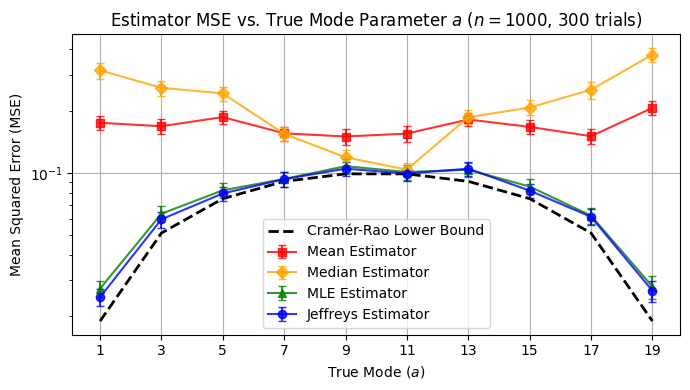


We see that mean and median are quite bad and their forms diverge from the Cramér-Rao lower bound shape. The median estimator perform worst when $a$ is not in the middle of the range. However the median is really efficient when $a=9$ or $11$

MLE and Jeffreys estimator follow the same trajectory and perform equally well. Their curve is really close to the Cramàr-Rao lower bound. When $a$ is not centered in the range they clearly overperforms the mean and median by $1$ order of magnitude.

Now I'll inspect two points to see if improving the grid resolution improves the estimator MSE. 


Results for a = 5:
MSE (low res pts): 7.642087e-02
MSE (high res pts): 7.642072e-02
Max Diff per est: 3.114992e-05


Results for a = 13:
MSE (low res pts): 9.028101e-02
MSE (high res pts): 9.028101e-02
Max Diff per est: 3.515912e-05






We see that the resulting MSE deviation is really close of the original estimate. This confirms that the low resolution grid captured well enough the sharply dynamic of the estimators. The observed MSE volatility is then an inherent finite-sample behavior of the estimator for our distribution and not a numerical integration artifact.



In [11]:
# TODO: answer Question 10, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

# parameters
b = 20
n = 1000
trials = 300
epsilon = 1e-5
a_vals = np.linspace(1, 19, 10)
rng = np.random.default_rng(seed=SEED)

# grid for posterior
a_quad = np.linspace(epsilon, b - epsilon, 801)
jeffreys_prior = 1.0 / np.sqrt(a_quad * (b - a_quad))
a_quad_row = a_quad[None, :]

# Storage
mses = { 'Mean': [], 'Median': [], 'MLE': [], 'Jeffreys': [] }
mc_ses = { 'Mean': [], 'Median': [], 'MLE': [], 'Jeffreys': [] }
crlb = []

for a in a_vals:
    crlb.append(a * (b - a) / n)
    
    ests = { 'Mean': np.zeros(trials), 'Median': np.zeros(trials), 
             'MLE': np.zeros(trials), 'Jeffreys': np.zeros(trials) }
    
    for t in range(trials):
        X = sample_triangular(a, b, n, rng)

        # mean
        ests['Mean'][t] = 3 * np.mean(X) - b
        
        # median
        m = np.median(X)
        if m >= b / 2:
            ests['Median'][t] = (m**2) / (b / 2)
        else:
            ests['Median'][t] = b - ((b - m)**2) / (b / 2)

        # likelihood
        X_col = X[:, None]        
        a_cand = X[None, :]
        pdf_mle = np.where(
            X_col <= a_cand, 
            X_col / (a_cand * b / 2), 
            (b - X_col) / ((b - a_cand) * b / 2)
        )
        ll_mle = np.sum(np.log(pdf_mle), axis=0)
        ests['MLE'][t] = a_cand[0, np.argmax(ll_mle)]
        
        # jeffrey posterior mean
        pdf_q = np.where(
            X_col <= a_quad_row, 
            X_col / (a_quad_row * b / 2), 
            (b - X_col) / ((b - a_quad_row) * b / 2)
        )
        ll_q = np.sum(np.log(pdf_q), axis=0)
        
        ll_max = np.max(ll_q)
        likelihood = np.exp(ll_q - ll_max)
        posterior_unnorm = likelihood * jeffreys_prior
        
        norm_const = np.trapezoid(posterior_unnorm, a_quad)
        ests['Jeffreys'][t] = np.trapezoid(posterior_unnorm * a_quad, a_quad) / norm_const

    # MSE and Monte Carlo Standard Error
    for k in mses:
        squared_errors = (ests[k] - a)**2
        mses[k].append(np.mean(squared_errors))
        mc_ses[k].append(np.std(squared_errors, ddof=1) / np.sqrt(trials))

# Plotting
plt.figure()

colors = {'Mean': 'red', 'Median': 'orange', 'MLE': 'green', 'Jeffreys': 'blue'}
markers = {'Mean': 's', 'Median': 'D', 'MLE': '^', 'Jeffreys': 'o'}

for k in mses:
    plt.errorbar(a_vals, mses[k], yerr=mc_ses[k], label=f'{k} Estimator', 
                 color=colors[k], marker=markers[k], capsize=3, alpha=0.8)

plt.plot(a_vals, crlb, 'k--', lw=2, label='Cramér-Rao Lower Bound')

plt.title('Estimator MSE vs. True Mode Parameter $a$ ($n=1000$, 300 trials)')
plt.xlabel('True Mode ($a$)')
plt.ylabel('Mean Squared Error (MSE)')
plt.yscale('log')
plt.xticks(np.arange(1, 20, 2))
plt.legend()
plt.tight_layout()
plt.show()

display(Markdown(r"""
We see that mean and median are quite bad and their forms diverge from the Cramér-Rao lower bound shape. The median estimator perform worst when $a$ is not in the middle of the range. However the median is really efficient when $a=9$ or $11$

MLE and Jeffreys estimator follow the same trajectory and perform equally well. Their curve is really close to the Cramàr-Rao lower bound. When $a$ is not centered in the range they clearly overperforms the mean and median by $1$ order of magnitude.

Now I'll inspect two points to see if improving the grid resolution improves the estimator MSE. 
"""))

test_cases = [5, 13]
grid_low_res = a_quad
grid_high_res = np.linspace(epsilon, b - epsilon, 10000)

prior_low_res = 1.0 / np.sqrt(grid_low_res * (b - grid_low_res))
prior_high = 1.0 / np.sqrt(grid_high_res * (b - grid_high_res))

grid_low_row = grid_low_res[None, :]
grid_high_row = grid_high_res[None, :]

rng = np.random.default_rng(seed=SEED)

for a in test_cases:
    est_low = np.zeros(trials)
    est_high = np.zeros(trials)
    
    for t in range(trials):
        X = sample_triangular(a, b, n, rng)
        X_col = X[:, None]
        
        # low res grid
        pdf_low = np.where(
            X_col <= grid_low_row, 
            X_col / (grid_low_row * b / 2), 
            (b - X_col) / ((b - grid_low_row) * b / 2)
        )
        ll_low = np.sum(np.log(pdf_low), axis=0)
        ll_low_max = np.max(ll_low)
        ll_low_max = np.max(ll_low)
        post_unnorm_low = np.exp(ll_low - ll_low_max) * prior_low_res
        norm_low = np.trapezoid(post_unnorm_low, grid_low_res)
        est_low[t] = np.trapezoid(post_unnorm_low * grid_low_res, grid_low_res) / norm_low
        
        # high res grid
        pdf_high = np.where(
            X_col <= grid_high_row, 
            X_col / (grid_high_row * b / 2), 
            (b - X_col) / ((b - grid_high_row) * b / 2)
        )
        ll_high = np.sum(np.log(pdf_high), axis=0)
        ll_high_max = np.max(ll_high)
        post_unnorm_high = np.exp(ll_high - ll_high_max) * prior_high
        norm_high = np.trapezoid(post_unnorm_high, grid_high_res)
        est_high[t] = np.trapezoid(post_unnorm_high * grid_high_res, grid_high_res) / norm_high

    # MSE
    mse_low = np.mean((est_low - a)**2)
    mse_high = np.mean((est_high - a)**2)
    
    # Compute max absolute difference between individual estimates
    max_diff = np.max(np.abs(est_low - est_high))

    print(f"Results for a = {a}:")
    print(f"MSE (low res pts): {mse_low:.6e}")
    print(f"MSE (high res pts): {mse_high:.6e}")
    print(f"Max Diff per est: {max_diff:.6e}")
    print("\n")

display(Markdown(r"""

We see that the resulting MSE deviation is really close of the original estimate. This confirms that the low resolution grid captured well enough the sharply dynamic of the estimators. The observed MSE volatility is then an inherent finite-sample behavior of the estimator for our distribution and not a numerical integration artifact.

"""))

Alex has changed the code. In the next questions, `full.npy` contains a new sample
with both $a$ and $b$ unknown. Neither parameter need equal the earlier value.
Continue treating parameters as continuous before discussing the integer code.

### Question 11 — Joint maximum-likelihood estimation

Load `full.npy`, report its size, and plot a density histogram. Estimate both
parameters by maximizing the likelihood under $0<a<b\le99$ and $b>\max_i x_i$.
Check numerical feasibility and compare several candidate values or starts.
Hint: for each fixed $b$, reuse the candidate-location method from Question 5,
then numerically maximize the resulting profile likelihood over $b$.

Size = 10000, range = [0.532, 77.500]
MLE: a = 41.5952, b = 77.9189, log-lik = -41648.504


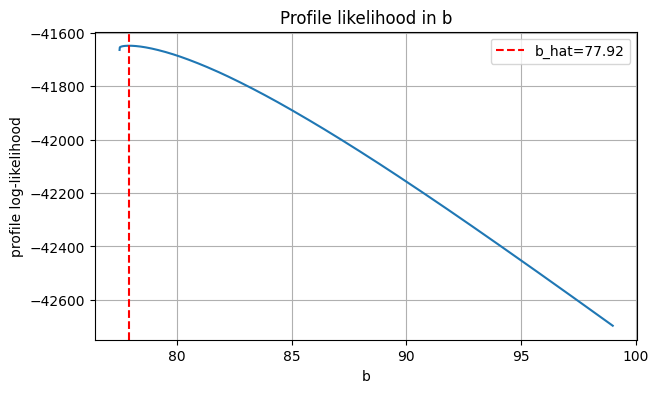

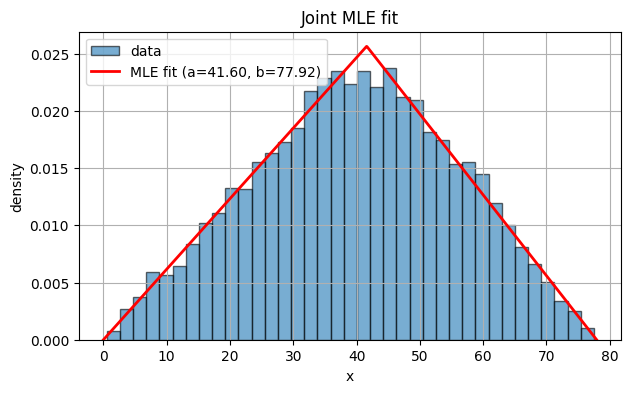


The first plot shows that we well computed the maximum of the likelihood.

The second plot shows a good fit which seems quite accurate. The theoretical distribution match the empirical data density. Our computations computed a realistic $a=42$ and $b=78$ for the data. 

Standard gradient-based optimization is inappropriate here because the likelihood surface is non-differentiable, we could have multiple maximum as seen before and that could cause initialization bias. By restricting the candidate values of $a$ to the observed data points and applying a grid search over $b$, we can guarantee numerical feasibility and systematically isolate the global maximum without relying on arbitrary starting values.


In [12]:
# TODO: answer Question 11, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

data_full = np.load("full.npy")
n = len(data_full)

x_sorted_full = np.sort(data_full)
print(f"Size = {n}, range = [{x_sorted_full[0]:.3f}, {x_sorted_full[-1]:.3f}]")

def profile_ll(xs, b):
    if b <= xs[-1]:
        return -np.inf, np.nan
    cand = np.unique(xs[(xs > 0) & (xs < b)])

    n = len(xs)
    a = np.atleast_1d(cand).astype(float)
    k = np.searchsorted(xs, a, side="right")                     # number of samples <= a
    cum_log_x = np.concatenate(([0.0], np.cumsum(np.log(xs))))   # sum of log x over first k
    suffix_log_bx = np.concatenate((np.cumsum(np.log(b - xs)[::-1])[::-1], [0.0]))  # sum of log(b-x) over samples > a
    ll = n*np.log(2/b) + cum_log_x[k] + suffix_log_bx[k] - k*np.log(a) - (n - k)*np.log(b - a)
    j = np.argmax(ll)
    return ll[j], cand[j]

def fit_joint(xs, b_max=99.0, n_coarse=2000, n_fine=400):
    b_lo = xs[-1] + 1e-6                                   # enforce b > max(x)
    bg = np.linspace(b_lo, b_max, n_coarse)
    ll = np.array([profile_ll(xs, b)[0] for b in bg])
    j = np.argmax(ll)
    bf = np.linspace(bg[max(j - 1, 0)], bg[min(j + 1, n_coarse - 1)], n_fine)
    llf = np.array([profile_ll(xs, b)[0] for b in bf])
    jf = np.argmax(llf)
    return profile_ll(xs, bf[jf])[1], bf[jf], llf[jf], (bg, ll)

a_hat, b_hat, ll_hat, (bg, ll_b) = fit_joint(x_sorted_full)
print(f"MLE: a = {a_hat:.4f}, b = {b_hat:.4f}, log-lik = {ll_hat:.3f}")

# profile likelihood 
fig = plt.figure()
plt.plot(bg, ll_b) 
plt.axvline(b_hat, color="r", ls="--", label=f"b_hat={b_hat:.2f}")
plt.xlabel("b")
plt.ylabel("profile log-likelihood")
plt.title("Profile likelihood in b")
plt.legend()
plt.show()

# plot fitted density
fig = plt.figure()
plt.hist(data_full, bins="auto", density=True, alpha=0.6, edgecolor="k", label="data")

t = np.linspace(0, b_hat, 1000)
plt.plot(t, np.where(t <= a_hat, 2*t/(a_hat*b_hat), 2*(b_hat - t)/(b_hat*(b_hat - a_hat))), "r-", lw=2,
            label=f"MLE fit (a={a_hat:.2f}, b={b_hat:.2f})")
plt.xlabel("x")
plt.ylabel("density")
plt.title("Joint MLE fit")
plt.legend()
plt.show()

display(Markdown(r"""
The first plot shows that we well computed the maximum of the likelihood.

The second plot shows a good fit which seems quite accurate. The theoretical distribution match the empirical data density. Our computations computed a realistic $a=42$ and $b=78$ for the data. 

Standard gradient-based optimization is inappropriate here because the likelihood surface is non-differentiable, we could have multiple maximum as seen before and that could cause initialization bias. By restricting the candidate values of $a$ to the observed data points and applying a grid search over $b$, we can guarantee numerical feasibility and systematically isolate the global maximum without relying on arbitrary starting values.
"""))

### Question 12 — Joint uncertainty and the code

Use 300 nonparametric bootstrap replicates to obtain marginal percentile 95%
intervals for $a$ and $b$ (you may increase this number). Display the bootstrap
estimates together in a scatter plot. Give a plausible integer code, list the
integer pairs inside the two marginal intervals, and explain why these intervals
do not guarantee unique or joint 95% recovery. Discuss the additional caution
needed when a parameter controls the support of a distribution.

95% percentile intervals
a -> [40.55, 42.25]
b -> [77.62, 78.23]
integer pairs inside the two marginal intervals
[(41, 78), (42, 78)]


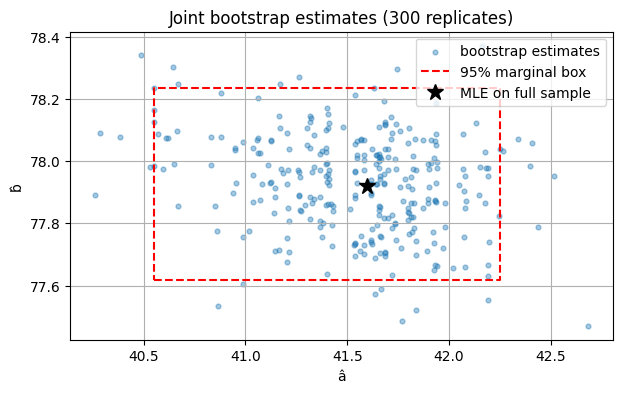


Our marginal intervals box is a rectangular bounding box, it is constructed by isolating independently the central $95\%$ of each parameter empirical distribution. This doesn't guarantee that the box represent the joint distribution as it could be an ellipsoid too (one variable influences the other). We effectively see that the bottom left corner is empty for example. 

The possible code is either $4178$ or $4278$.

We must also be careful about the fact that our boostrap is truncated by $max(x_i)$ as replicates are drawn from the observed sample and we could missrepresent the tail of the distribution in the case where our collected data is not large enough. 


In [13]:
# TODO: answer Question 12, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

nbr_bootsrap = 300
rng = np.random.default_rng(SEED)
boot = np.empty((nbr_bootsrap, 2))

for i in range(nbr_bootsrap):
    xb = np.sort(rng.choice(data_full, size=n, replace=True))
    a_b, b_b, _, _ = fit_joint(xb, n_coarse=300, n_fine=200)
    boot[i] = a_b, b_b

a_lo, a_up = np.percentile(boot[:, 0], [2.5, 97.5])
b_lo_, b_up = np.percentile(boot[:, 1], [2.5, 97.5])
print("95% percentile intervals")
print(f"a -> [{a_lo:.2f}, {a_up:.2f}]")
print(f"b -> [{b_lo_:.2f}, {b_up:.2f}]")

a_ints = range(int(np.ceil(a_lo)), int(np.floor(a_up)) + 1)
b_ints = range(int(np.ceil(b_lo_)), int(np.floor(b_up)) + 1)
print("integer pairs inside the two marginal intervals")
print([(a, b) for a in a_ints for b in b_ints])

fig, ax = plt.subplots()
ax.scatter(boot[:, 0], boot[:, 1], alpha=0.4, s=12, label="bootstrap estimates")
ax.plot([a_lo, a_up, a_up, a_lo, a_lo], [b_lo_, b_lo_, b_up, b_up, b_lo_], "r--", label="95% marginal box")
ax.plot(a_hat, b_hat, "k*", ms=12, label="MLE on full sample")
ax.set(xlabel="â", ylabel="b̂", title=f"Joint bootstrap estimates ({nbr_bootsrap} replicates)")
ax.legend()
plt.show()

display(Markdown(r"""
Our marginal intervals box is a rectangular bounding box, it is constructed by isolating independently the central $95\%$ of each parameter empirical distribution. This doesn't guarantee that the box represent the joint distribution as it could be an ellipsoid too (one variable influences the other). We effectively see that the bottom left corner is empty for example. 

The possible code is either $4178$ or $4278$.

We must also be careful about the fact that our boostrap is truncated by $max(x_i)$ as replicates are drawn from the observed sample and we could missrepresent the tail of the distribution in the case where our collected data is not large enough. 
"""))

### Question 13 — Joint moment estimation (optional)

Can the population mean and median identify $(a,b)$? Derive candidate solutions
for both median branches, check the parameter constraints, and try them on
`full.npy`. Explain why finite-sample inversion can be unstable or inadmissible.

In [14]:
# TODO: answer Question 13, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display (Markdown(r"""
We can identify the parameters $(a, b)$ by solving the system of equations we found for the mean and median. We must still distinguish the cases $a \geq b/2$ or $a < b/2$

**Case 1**: $a \geq b/2$
$$\begin{cases}
\mu = \frac{a+b}{3}\\
m = \sqrt{ab/2}
\end{cases}$$

We find from the first equation $ b = 3\mu -a$ and we substitute in the second.

$$m = \sqrt{\frac{a(3\mu-a)}{2}} \rightarrow 2m^2 = a(3\mu-a) \rightarrow
a^2 - 3 \mu a + 2 m^2 = 0 \rightarrow a = \frac{3\mu - \sqrt{9\mu^2 - 8m^2}}{2}$$

$$ b = 3\mu -a = 3\mu-\frac{3\mu - \sqrt{9\mu^2 - 8m^2}}{2} = \frac{3\mu + \sqrt{9\mu^2 - 8m^2}}{2}$$

For this results to be real we need $\Delta = 9\mu^2 - 8m^2 > 0$

**Case 2**: $a < b/2$
$$\begin{cases}
\mu = \frac{a+b}{3}\\
m = b - \sqrt{\frac{b(b-a)}{2}}
\end{cases}$$

We find from the first equation $ a = 3\mu -b$ and we substitute in the second.
$$m = b - \sqrt{\frac{b(b-( 3\mu -b))}{2}} = b - \sqrt{\frac{2b^2-3\mu b}{2}}\rightarrow (b-m)^2 = \frac{2b^2 - 3\mu b}{2}$$
$$2b^2 -4mb + 2m^2 = 2b^2 -3\mu b\rightarrow -4bm + 2m^2 = -3\mu b \rightarrow b(3\mu -4m) = -2m^2$$
$$b = \frac{-2m^2}{3\mu-4m} = \frac{2m^2}{4m-3\mu}$$
$$a = 3\mu -b = 3\mu - \frac{2m^2}{4m-3\mu}$$

In order to respect the constraint $0 < a < b$ we need to have $4m-3\mu > 0$.

For both branches we must finally check that our final computed values $a$ and $b$ respect the problem constraints which are $0<a<b$ and the $b>max(x_i)$. 
"""))

mu_hat = np.mean(data_full)
m_hat = np.median(data_full)

print(f"Sample Mean: {mu_hat:.4f}")
print(f"Sample Median: {m_hat:.4f}")

if mu_hat <= m_hat:
    print("Case 1 applies (mu <= m).")

    discriminant = 9 * mu_hat**2 - 8 * m_hat**2
    if discriminant < 0:
        raise ValueError("Discriminant is negative. Cannot compute real roots.")
        
    a_est = (3 * mu_hat - np.sqrt(discriminant)) / 2
    b_est = (3 * mu_hat + np.sqrt(discriminant)) / 2
    
else:
    print("Case 2 applies (mu > m).")
    denom = 4 * m_hat - 3 * mu_hat
    if denom == 0:
        raise ValueError("Denominator is zero. Cannot compute estimates.")
        
    b_est = (2 * m_hat**2) / denom
    a_est = 3 * mu_hat - b_est
    
print(f"Moment Estimates -> a: {a_est:.4f}, b: {b_est:.4f}")

max_x = np.max(data_full)
if b_est <= max_x:
    print(f"Invalid b ({b_est:.4f}) <= max(X) ({max_x:.4f})")
elif a_est < 0:
    print(f"Invalid a ({a_est:.4f}) < 0")
else:
    print(f"Estimation in expected range, code is {int(a_est)}{int(b_est)}")

display(Markdown(r"""
We computed the code $4178$ with the moment method. However we 
see that there is one condition on each case that when it isn't respected makes the computations unfeasible. 
This could happen due to sampling noise or bias datasets.

As this estimators rely entirely on central tendencies, it is possible to find an estimation of $b$ which is $< max(x_i)$ which would obviously be wrong as we would assign a probability of zero to data points which are been observed. So we must be careful to check that our estimation $\hat a$ and $\hat b$ still respects the problem constraints, $0 < \hat a < max(x_i) < \hat b$
"""))


We can identify the parameters $(a, b)$ by solving the system of equations we found for the mean and median. We must still distinguish the cases $a \geq b/2$ or $a < b/2$

**Case 1**: $a \geq b/2$
$$\begin{cases}
\mu = \frac{a+b}{3}\\
m = \sqrt{ab/2}
\end{cases}$$

We find from the first equation $ b = 3\mu -a$ and we substitute in the second.

$$m = \sqrt{\frac{a(3\mu-a)}{2}} \rightarrow 2m^2 = a(3\mu-a) \rightarrow
a^2 - 3 \mu a + 2 m^2 = 0 \rightarrow a = \frac{3\mu - \sqrt{9\mu^2 - 8m^2}}{2}$$

$$ b = 3\mu -a = 3\mu-\frac{3\mu - \sqrt{9\mu^2 - 8m^2}}{2} = \frac{3\mu + \sqrt{9\mu^2 - 8m^2}}{2}$$

For this results to be real we need $\Delta = 9\mu^2 - 8m^2 > 0$

**Case 2**: $a < b/2$
$$\begin{cases}
\mu = \frac{a+b}{3}\\
m = b - \sqrt{\frac{b(b-a)}{2}}
\end{cases}$$

We find from the first equation $ a = 3\mu -b$ and we substitute in the second.
$$m = b - \sqrt{\frac{b(b-( 3\mu -b))}{2}} = b - \sqrt{\frac{2b^2-3\mu b}{2}}\rightarrow (b-m)^2 = \frac{2b^2 - 3\mu b}{2}$$
$$2b^2 -4mb + 2m^2 = 2b^2 -3\mu b\rightarrow -4bm + 2m^2 = -3\mu b \rightarrow b(3\mu -4m) = -2m^2$$
$$b = \frac{-2m^2}{3\mu-4m} = \frac{2m^2}{4m-3\mu}$$
$$a = 3\mu -b = 3\mu - \frac{2m^2}{4m-3\mu}$$

In order to respect the constraint $0 < a < b$ we need to have $4m-3\mu > 0$.

For both branches we must finally check that our final computed values $a$ and $b$ respect the problem constraints which are $0<a<b$ and the $b>max(x_i)$. 


Sample Mean: 39.8411
Sample Median: 40.1271
Case 1 applies (mu <= m).
Moment Estimates -> a: 41.0241, b: 78.4993
Estimation in expected range, code is 4178



We computed the code $4178$ with the moment method. However we 
see that there is one condition on each case that when it isn't respected makes the computations unfeasible. 
This could happen due to sampling noise or bias datasets.

As this estimators rely entirely on central tendencies, it is possible to find an estimation of $b$ which is $< max(x_i)$ which would obviously be wrong as we would assign a probability of zero to data points which are been observed. So we must be careful to check that our estimation $\hat a$ and $\hat b$ still respects the problem constraints, $0 < \hat a < max(x_i) < \hat b$


## Part II — Supervised learning

We now study a separate problem: classifying images of people with and without
a face mask. The aim is to compare simple supervised models and understand how
additional, class-biased data affect learning. This is an educational benchmark,
not a validated deployment system.

The bundled files follow the current 2026 preprocessing rule, with fixed seeds
and exact duplicate images removed before splitting:
- `data/train.npz`: a small labelled sample from the source training partition;
- `data/extra.npz`: additional labelled images, introduced in Question 21;
- `data/test.npz`: a fixed final test partition; leave it unopened until Question 29.

Images are stored as 128×128 RGB arrays in channel-first order `(3, 128, 128)`.
Labels are **0 = with mask**, **1 = without mask**. To make repeated fitting practical,
the provided `image_features` computes fixed 4×4 pixel-block averages, yielding
32×32 RGB images, scaled to [0,1] and flattened to 3,072 features. It learns nothing
from the data. All models and the evaluator use this same representation.

Use an internal training/validation split of `train.npz`. Hyperparameters are
chosen by five-fold cross-validation on the internal training portion. The small
validation set supports development comparisons; it is not the final test set.
Fit scalers only inside training folds. Keep validation and final test observations
out of resampling and fitting. Use **balanced accuracy** as the primary selection
metric and report ordinary accuracy as well. For two classes, balanced accuracy
is the average of the two class recalls. This supports the later imbalance study.

The local final test is accessible, not secret. Evaluate it only after freezing
your choices. Do not claim hidden-test guarantees or select a new model after
seeing final test scores. Model rankings are empirical results, not required answers.

The `search` helper below uses `GridSearchCV` to try different combinations of
hyperparameters and select the one with the best mean cross-validation score
(here, balanced accuracy).

In [15]:
# PROVIDED: data access and deterministic feature representation.
from evaluation import load_file, image_features, scores, evaluate
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

images, labels = load_file("train")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

def search(model, grid, X, y):
    # One worker limits peak memory; randomness is set explicitly in estimators.
    return GridSearchCV(model, grid, scoring=SCORING, refit="balanced_accuracy",
                        # verbose=1, # show overall progress
                        cv=CV, n_jobs=1, error_score="raise", return_train_score=True).fit(X, y)

### Question 14 — Explore the image dataset

Report the image-array shape, pixel range, and class counts. Plot six labelled
images. Is this small dataset approximately balanced? Explain why label counts
matter when interpreting ordinary accuracy.

Image array shape: (185, 3, 128, 128) -> 185 images, 3 channels, 128 height, 128 width
Pixel range: [0, 255]
Class 0 distribution: 99
Class 1 distribution: 86


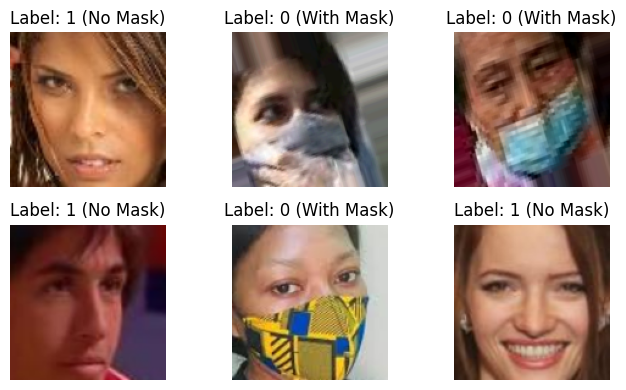


By selecting 6 random images among our 185 we have a perfect balanced data subset with 3 "with mask" and 3 "no mask". We also see that with a $99$ data of class $0$ vs $86$ data of class $1$ accross the complete data, the training dataset is well balanced.

Ordinary accuracy is important because if the dataset was strongly bias, for example 170 over the 185 images with "no mask", the model would learn to always say "no mask" and still achieve a $>90\%$ accuracy.


In [16]:
# TODO: answer Question 14, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

print(f"Image array shape: {images.shape} -> " + 
      f"{images.shape[0]} images, {images.shape[1]} channels, {images.shape[2]} height, {images.shape[3]} width")
print(f"Pixel range: [{images.min()}, {images.max()}]")

unique_classes, counts = np.unique(labels, return_counts=True)
class_distribution = dict(zip(unique_classes, counts))

print(f"Class 0 distribution: {class_distribution[0]}")
print(f"Class 1 distribution: {class_distribution[1]}")

# Select 6 random images
np.random.seed(SEED)
random_indices = np.random.choice(len(images), size=6, replace=False)

#  Plot
fig, axes = plt.subplots(2, 3)
for i, ax in enumerate(axes.flat):
    # Convert from (C, H, W) to (H, W, C) for plotting
    img_plot = np.transpose(images[random_indices[i]], (1, 2, 0))
            
    ax.imshow(img_plot)

    if labels[random_indices[i]] == 1:
        label_name = "No Mask"
    else:
        label_name = "With Mask"
    
    ax.set_title(f"Label: {labels[random_indices[i]]} ({label_name})")
    ax.axis("off")

plt.tight_layout()
plt.show()

display(Markdown(r"""
By selecting 6 random images among our 185 we have a perfect balanced data subset with 3 "with mask" and 3 "no mask". We also see that with a $99$ data of class $0$ vs $86$ data of class $1$ accross the complete data, the training dataset is well balanced.

Ordinary accuracy is important because if the dataset was strongly bias, for example 170 over the 185 images with "no mask", the model would learn to always say "no mask" and still achieve a $>90\%$ accuracy.
"""))

### Question 15 — Feature vectors, split, and baseline

Use `image_features` and report the feature-array shape. Make a stratified 80/20
training/validation split with `random_state=SEED`. Check both class counts.
Fit a majority-class dummy classifier and report training and validation accuracy
and balanced accuracy. Explain why flattening preserves pixel values but does not
give these models explicit spatial structure.

In [17]:
# TODO: answer Question 15, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

# Extract features from images
X_image_features = image_features(images)
print(f"Feature array shape: {X_image_features.shape}")

# 80/20 split
X_train, X_val, y_train, y_val = train_test_split(
    X_image_features, labels, test_size=0.2, stratify=labels, random_state=SEED
)
print(f"Training class counts: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Validation class counts: {dict(zip(*np.unique(y_val, return_counts=True)))}")

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

for split_name, X_split, y_split in [("Train", X_train, y_train), ("Val", X_val, y_val)]:
    y_pred = dummy.predict(X_split)
    acc = accuracy_score(y_split, y_pred)
    b_acc = balanced_accuracy_score(y_split, y_pred)
    print(f"{split_name} - Accuracy: {acc:.3f}, Balanced Accuracy: {b_acc:.3f}")

display(Markdown(r"""
Flattening converts the $3\times 128\times 128$ 3D array into a 1D array of length 3,072 by first reducing the image to a $32\times 32$ pixel grid by averaging $4\times 4$ pixel blocs for each channel and then unrolling it into a 1D array ($32\cdot 32 \cdot 3 = 3072$). 

Flattening preserves the important pixel values but loses spatial awareness, as the model no longer knows which pixels are side-by-side to another. For example, if the i-th element of the array represents a pixel on one side of the image, the next element could correspond to a pixel on the other side boundary, even though they are not adjacent in the original image. We also lose information about which pixels were above or below a given pixel. The models will never know any of this and will treat the 3072 features as coordinates with no particular order.

The majority DummyClassifier logically gives a balanced accuracy of 0.5 by construction so our model must beat that to be any kind of useful.
"""))

Feature array shape: (185, 3072)
Training class counts: {np.int64(0): np.int64(79), np.int64(1): np.int64(69)}
Validation class counts: {np.int64(0): np.int64(20), np.int64(1): np.int64(17)}
Train - Accuracy: 0.534, Balanced Accuracy: 0.500
Val - Accuracy: 0.541, Balanced Accuracy: 0.500



Flattening converts the $3\times 128\times 128$ 3D array into a 1D array of length 3,072 by first reducing the image to a $32\times 32$ pixel grid by averaging $4\times 4$ pixel blocs for each channel and then unrolling it into a 1D array ($32\cdot 32 \cdot 3 = 3072$). 

Flattening preserves the important pixel values but loses spatial awareness, as the model no longer knows which pixels are side-by-side to another. For example, if the i-th element of the array represents a pixel on one side of the image, the next element could correspond to a pixel on the other side boundary, even though they are not adjacent in the original image. We also lose information about which pixels were above or below a given pixel. The models will never know any of this and will treat the 3072 features as coordinates with no particular order.

The majority DummyClassifier logically gives a balanced accuracy of 0.5 by construction so our model must beat that to be any kind of useful.


### Question 16 — Logistic Regression and regularization

Fit Logistic Regression with $\ell_1$ and $\ell_2$ penalties, initially using $C=1$.
Use a `StandardScaler` pipeline and a solver supporting the chosen penalty.
Report training and validation metrics. Explain the difference between the two
penalties and why a single split cannot establish a universal winner.

In [18]:
# TODO: answer Question 16, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

l1_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l1', C=1.0, solver='liblinear', random_state=SEED, max_iter=1000)
)

l2_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l2', C=1.0, random_state=SEED, max_iter=1000)
)

for name, pipeline in [("L1 Penalty", l1_pipeline), ("L2 Penalty", l2_pipeline)]:
    pipeline.fit(X_train, y_train)
    
    train_acc = accuracy_score(y_train, pipeline.predict(X_train))
    train_bacc = balanced_accuracy_score(y_train, pipeline.predict(X_train))
    
    val_acc = accuracy_score(y_val, pipeline.predict(X_val))
    val_bacc = balanced_accuracy_score(y_val, pipeline.predict(X_val))
    
    print(f"{name} pipeline results")
    print(f"Training metrics - accuracy: {train_acc:.3f}, balanced accuracy: {train_bacc:.3f}")
    print(f"Validation metrics - accuracy: {val_acc:.3f}, balanced accuracy: {val_bacc:.3f}")

    w = pipeline[-1].coef_.ravel()
    print(f"Non-zero weights {np.sum(w != 0)}/{w.size}\n")

display(Markdown(r"""
$\ell_1$ penalty contrains the sum of the absolute values of the weights. This performs a kind of feature selection by setting a lot of weights equals to $0$, we effectively see that only $74$ weights finished to be non-zero.

$\ell_2$ penalty contrains the sum of the squared values of the weights. It's effect is more to distribute importance accros features instead of dsicarding some of them. In practice we can observe that all weights are not null so the model considere all features.

A single split cannot define a universal winner as it is influecnes by the random allocations of the samples in the train/test datasets. A model could outperform another one on a certain split and loose in another. This is why we are logically asked to introduce cross-validation in the next question. 
"""))

L1 Penalty pipeline results
Training metrics - accuracy: 1.000, balanced accuracy: 1.000
Validation metrics - accuracy: 0.919, balanced accuracy: 0.925
Non-zero weights 74/3072

L2 Penalty pipeline results
Training metrics - accuracy: 1.000, balanced accuracy: 1.000
Validation metrics - accuracy: 0.892, balanced accuracy: 0.900
Non-zero weights 3072/3072




$\ell_1$ penalty contrains the sum of the absolute values of the weights. This performs a kind of feature selection by setting a lot of weights equals to $0$, we effectively see that only $74$ weights finished to be non-zero.

$\ell_2$ penalty contrains the sum of the squared values of the weights. It's effect is more to distribute importance accros features instead of dsicarding some of them. In practice we can observe that all weights are not null so the model considere all features.

A single split cannot define a universal winner as it is influecnes by the random allocations of the samples in the train/test datasets. A model could outperform another one on a certain split and loose in another. This is why we are logically asked to introduce cross-validation in the next question. 


### Question 17 — Cross-validate Logistic Regression

Cross-validate penalties `['l1', 'l2']` and seven logarithmically spaced values of
$C$ from $10^{-3}$ to $10^3$. Use the supplied CV/selection convention. Report the
selected parameters, mean CV balanced accuracy and its fold standard deviation,
and validation metrics. Is the tuned model necessarily better on validation than
both models from Question 16? Explain.

In [19]:
# TODO: answer Question 17, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='liblinear', random_state=SEED, max_iter=2000)
)

C_values = np.logspace(-3, 3, 7)

param_grid = {
    'logisticregression__penalty': ['l1', 'l2'],
    'logisticregression__C': C_values
}

grid_search = search(pipeline, param_grid, X_train, y_train)

best_idx = grid_search.best_index_
best_params = grid_search.best_params_
mean_cv_bacc = grid_search.cv_results_['mean_test_balanced_accuracy'][best_idx]
std_cv_bacc = grid_search.cv_results_['std_test_balanced_accuracy'][best_idx]

print(f"Selected parameters: {best_params}")
print(f"Mean CV Balanced Accuracy: {mean_cv_bacc:.3f} (± {std_cv_bacc:.3f})")

# Evaluate on validation split
best_model = grid_search.best_estimator_
val_pred = best_model.predict(X_val)
print(f"Validation - Accuracy: {accuracy_score(y_val, val_pred):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, val_pred):.3f}")

display(Markdown(r"""
The cross-validation selection selected a $C$ of $10^3$ and a $\ell_2$ penalty model that achieves a $92.9\%$ of mean CV balanced accuracy with a stand deviation of $\pm 3.3\%$. We observe that the choosen $C$ is at the limit of what we authorized.

We see that there is still a generalization gap (difference of $> 5\%$ in balanced accuracy). And with a balanced accuracy of $87.5\%$ our new model performs worst than the two previous ones. 

So for the questions *"Is the tuned model necessarily better on validation than both models ?"* we found a counter-example and can answer no.
"""))

Selected parameters: {'logisticregression__C': np.float64(1000.0), 'logisticregression__penalty': 'l2'}
Mean CV Balanced Accuracy: 0.929 (± 0.033)
Validation - Accuracy: 0.865
Balanced Accuracy: 0.875



The cross-validation selection selected a $C$ of $10^3$ and a $\ell_2$ penalty model that achieves a $92.9\%$ of mean CV balanced accuracy with a stand deviation of $\pm 3.3\%$. We observe that the choosen $C$ is at the limit of what we authorized.

We see that there is still a generalization gap (difference of $> 5\%$ in balanced accuracy). And with a balanced accuracy of $87.5\%$ our new model performs worst than the two previous ones. 

So for the questions *"Is the tuned model necessarily better on validation than both models ?"* we found a counter-example and can answer no.


### Question 18 — Linear SVM

Fit a scaled linear SVM and cross-validate the same seven values of $C$.
Report selected parameters, CV and validation results, and compare the training
objectives of SVM and Logistic Regression. Keep this comparison empirical: neither
model is required to win. Address convergence warnings if any occur.

In [20]:
# TODO: answer Question 18, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

pipe_svm = make_pipeline(
    StandardScaler(),
    LinearSVC(random_state=SEED, max_iter=10000, dual="auto") 
)

param_grid_svm = {
    'linearsvc__C': C_values
}

grid_svm = search(pipe_svm, param_grid_svm, X_train, y_train)

best_idx_svm = grid_svm.best_index_
best_params_svm = grid_svm.best_params_
mean_cv_bacc_svm = grid_svm.cv_results_['mean_test_balanced_accuracy'][best_idx_svm]
std_cv_bacc_svm = grid_svm.cv_results_['std_test_balanced_accuracy'][best_idx_svm]

print(f"Selected parameters: {best_params_svm}")
print(f"Mean CV Balanced Accuracy: {mean_cv_bacc_svm:.3f} (± {std_cv_bacc_svm:.3f})")

# validation split
best_svm = grid_svm.best_estimator_
val_pred_svm = best_svm.predict(X_val)
print(f"Validation - Accuracy: {accuracy_score(y_val, val_pred_svm):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, val_pred_svm):.3f}")

display(Markdown(r"""
To avoid convergence warning we just need to set the *max_iter* parameter large enough. 

We see that the model reaches the same balanced accuracy ($87.5\%$) in validation as the previous logistic model. But the SVM as achieved it by choseing a strong regularization ($C=0.01$) whereas the logistic regression model opted for a small regularization ($C=1000$)

Training objectives comparison: 

- SVM: optimizes to find the biggest margin possible, penalize points on the wrong side of the margin, don't penalize points on the correct side of the margin (Hinge loss function)

- Logistic regression: optimizes log-likelihood of the observed data point, it penalizes point even if it's correctly classified (even if it's a really little amount). It tries to push the probabilites to $0$ and $1$ as much as possible in the dataset. 

As both models are regularized linear mdodel in a $3072$ dimensional space, It's possible that they found the very similar separating hyperplanes.
"""))

Selected parameters: {'linearsvc__C': np.float64(0.01)}
Mean CV Balanced Accuracy: 0.928 (± 0.049)
Validation - Accuracy: 0.865
Balanced Accuracy: 0.875



To avoid convergence warning we just need to set the *max_iter* parameter large enough. 

We see that the model reaches the same balanced accuracy ($87.5\%$) in validation as the previous logistic model. But the SVM as achieved it by choseing a strong regularization ($C=0.01$) whereas the logistic regression model opted for a small regularization ($C=1000$)

Training objectives comparison: 

- SVM: optimizes to find the biggest margin possible, penalize points on the wrong side of the margin, don't penalize points on the correct side of the margin (Hinge loss function)

- Logistic regression: optimizes log-likelihood of the observed data point, it penalizes point even if it's correctly classified (even if it's a really little amount). It tries to push the probabilites to $0$ and $1$ as much as possible in the dataset. 

As both models are regularized linear mdodel in a $3072$ dimensional space, It's possible that they found the very similar separating hyperplanes.


### Question 19 — Random Forest

Train a Random Forest and cross-validate `n_estimators=[30, 100]`,
`max_depth=[10, None]`, and `criterion=['gini', 'entropy']`. Fix its random state.
Report the selected parameters, CV and validation metrics. Explain how this model
differs from the linear models and why increasing depth is not automatically better.

In [21]:
# TODO: answer Question 19, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

rf = RandomForestClassifier(random_state=SEED)
param_grid_rf = {
    'n_estimators': [30, 100],
    'max_depth': [10, None],
    'criterion': ['gini', 'entropy']
}

grid_rf = search(rf, param_grid_rf, X_train, y_train)

best_idx_rf = grid_rf.best_index_
best_params_rf = grid_rf.best_params_
mean_cv_bacc_rf = grid_rf.cv_results_['mean_test_balanced_accuracy'][best_idx_rf]
std_cv_bacc_rf = grid_rf.cv_results_['std_test_balanced_accuracy'][best_idx_rf]

print(f"Selected parameters: {best_params_rf}")
print(f"Mean CV Balanced Accuracy: {mean_cv_bacc_rf:.3f} (± {std_cv_bacc_rf:.3f})")

best_rf = grid_rf.best_estimator_
val_pred_rf = best_rf.predict(X_val)
print(f"Validation - Accuracy: {accuracy_score(y_val, val_pred_rf):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, val_pred_rf):.3f}")

display(Markdown(r"""
The model reaches a balanced accuracy in validation of $89.6\%$.

First as random forest is just multiple decision-trees. It doesn't require to scale the input data. They split the features based on thresholds instead than geometric distances (SVM) or gradient descent (logistic regression).

Secondly linear models are seeking one unique hyperplane to separates the two classes. A random forest is a group of decision-trees that can leanr to partition the space into more complex shapes with boundaries orthogonal to the axis. It can therefore handle more difficult and non-linear problems.

Increasing tree depth isn't always a good idea as it could leads to overfitting, if it is not restricted we could finish with only pure leaf even for outlier data points. Limiting the tree-depth then act as a form of regularization. In our case we see that the CV process has choosen to limit the tree depth. 
"""))

Selected parameters: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 30}
Mean CV Balanced Accuracy: 0.865 (± 0.067)
Validation - Accuracy: 0.892
Balanced Accuracy: 0.896



The model reaches a balanced accuracy in validation of $89.6\%$.

First as random forest is just multiple decision-trees. It doesn't require to scale the input data. They split the features based on thresholds instead than geometric distances (SVM) or gradient descent (logistic regression).

Secondly linear models are seeking one unique hyperplane to separates the two classes. A random forest is a group of decision-trees that can leanr to partition the space into more complex shapes with boundaries orthogonal to the axis. It can therefore handle more difficult and non-linear problems.

Increasing tree depth isn't always a good idea as it could leads to overfitting, if it is not restricted we could finish with only pure leaf even for outlier data points. Limiting the tree-depth then act as a form of regularization. In our case we see that the CV process has choosen to limit the tree depth. 


### Question 20 — Compare the original-data models

Compare the tuned Logistic Regression, SVM, and Random Forest in one table of CV,
training, and validation metrics. Explain any train–validation gap. How many
percentage points of ordinary validation accuracy correspond to one image?
Does the table justify claiming that one algorithm is always best?

In [22]:
# TODO: answer Question 20, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

models = {
    "Logistic Regression": grid_search,
    "Linear SVM": grid_svm,
    "Random Forest": grid_rf
}

results = []
for name, grid in models.items():
    best_model = grid.best_estimator_
    
    train_pred = best_model.predict(X_train)
    val_pred = best_model.predict(X_val)
    
    best_cv_bacc = grid.cv_results_['mean_test_balanced_accuracy'][grid.best_index_]
    
    results.append({
        "Model": name,
        "Train B-Acc": balanced_accuracy_score(y_train, train_pred),
        "CV B-Acc": best_cv_bacc,
        "Val Acc": accuracy_score(y_val, val_pred),
        "Val B-Acc": balanced_accuracy_score(y_val, val_pred)
    })

df_results = pd.DataFrame(results)
print(df_results)

print(f"\nTotal validation images: {len(y_val)}")
print(f"One validation image = {(1.0 / len(y_val)):.2%} points of accuracy.")

nbr_correct_image_regression = int(df_results.loc[df_results['Model'] == "Logistic Regression", 'Val Acc'].item() * len(y_val))
nbr_correct_image_SVM = int(df_results.loc[df_results['Model'] == "Linear SVM", 'Val Acc'].item() * len(y_val))
nbr_correct_image_RF = int(df_results.loc[df_results['Model'] == "Random Forest", 'Val Acc'].item() * len(y_val))

print("\nNumber of correctly classified images in validation split:")
print(f"  Logistic Regression {nbr_correct_image_regression} correct images")
print(f"  Linear SVM {nbr_correct_image_SVM} correct images")
print(f"  Random Forest {nbr_correct_image_RF} correct images")

display(Markdown(r"""
The training balanced accuracy is 1.0 across all three models. With a lot of features and only a small amount of samples, all three of them have completely memorized the training set.

We see that a model gains $2.70\%$ points of accuracy each time he classify correctly an image in the validation test. We see that the random forest has classified correctly just one more images than the other two which is not a lot on 37 total images. Thus we cannot determine a clear winner and we can say that no model is the best one as it heavily depends on parameters/regularization. 
"""))

                 Model  Train B-Acc  CV B-Acc   Val Acc  Val B-Acc
0  Logistic Regression          1.0  0.928690  0.864865   0.875000
1           Linear SVM          1.0  0.928274  0.864865   0.875000
2        Random Forest          1.0  0.864940  0.891892   0.895588

Total validation images: 37
One validation image = 2.70% points of accuracy.

Number of correctly classified images in validation split:
  Logistic Regression 32 correct images
  Linear SVM 32 correct images
  Random Forest 33 correct images



The training balanced accuracy is 1.0 across all three models. With a lot of features and only a small amount of samples, all three of them have completely memorized the training set.

We see that a model gains $2.70\%$ points of accuracy each time he classify correctly an image in the validation test. We see that the random forest has classified correctly just one more images than the other two which is not a lot on 37 total images. Thus we cannot determine a clear winner and we can say that no model is the best one as it heavily depends on parameters/regularization. 


Additional labelled data have become available in `extra.npz`. The format matches
the original images, but the collection process may have changed its composition.
Inspect it before deciding how to use it. Do not replace the validation or test sets
with this additional dataset. Keep the same feature representation throughout.

### Question 21 — Inspect the extra data

Load `extra.npz`, report its size and class counts, and explain its limitation.
Can it still provide useful training information together with the original
two-class data? Distinguish more observations from more observations of each class.

In [23]:
# TODO: answer Question 21, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

images_extra, labels_extra = load_file("extra")

print(f"Extra data shape: {images_extra.shape} -> {images_extra.shape[0]} images, {images_extra.shape[1]} channels, {images_extra.shape[2]} height, {images_extra.shape[3]} width")
print(f"Pixel range: [{images_extra.min()}, {images_extra.max()}]")

unique_extra, counts_extra = np.unique(labels_extra, return_counts=True)
print(f"Extra class counts: {dict(zip(unique_extra, counts_extra))}")

display(Markdown(r"""
We see that we now have a lot of extra data ($n = 4459$) but it is extremly bias as we have $100\%$ of images of class $0$ ("with mask") and no class $1$ image.

If we now train a model on the overall sample without doing anything the model will likely just learn to predict "with mask" for almost every image and we'll lose the possibility to actively find the people without a mask.

However we don't want to reject this images as it can still be valuable data, we now have new examples of lightning, angles, colors, etc of people with a mask. We just need to account for the imbalance in the model training phase.
"""))

Extra data shape: (4459, 3, 128, 128) -> 4459 images, 3 channels, 128 height, 128 width
Pixel range: [0, 255]
Extra class counts: {np.int64(0): np.int64(4459)}



We see that we now have a lot of extra data ($n = 4459$) but it is extremly bias as we have $100\%$ of images of class $0$ ("with mask") and no class $1$ image.

If we now train a model on the overall sample without doing anything the model will likely just learn to predict "with mask" for almost every image and we'll lose the possibility to actively find the people without a mask.

However we don't want to reject this images as it can still be valuable data, we now have new examples of lightning, angles, colors, etc of people with a mask. We just need to account for the imbalance in the model training phase.


### Question 22 — Evaluate existing models on extra

Evaluate the already-fitted models from Questions 17–19 on `extra`; **do not refit
them**. Report ordinary accuracy. What class-specific quantity does it estimate?
Can a higher score here than on the two-class validation set establish better
overall classification? Explain why all three fitted models can make these
predictions even though the evaluation labels contain only one class.

In [24]:
# TODO: answer Question 22, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

X_extra = image_features(images_extra)

# Evaluate the models fitted in Q17-Q19
for name, grid in models.items():
    best_model = grid.best_estimator_
    y_pred_extra = best_model.predict(X_extra)
    acc_extra = accuracy_score(labels_extra, y_pred_extra)
    
    print(f"{name} - Accuracy on Extra: {acc_extra:.3f}")

display(Markdown(r"""
As the extra dataset contains only images of class $0$, this will evaluate the recall of class $0$ (which is defined as $\frac{\text{number of correct predictions of class }0}{\text{total number of true class } 0}$). It represents the number proportion of people with mask the model indentifies correctly. We see that the random forest has from far the best recall score for class $0$ among the three models we trained earlier.

A higher score here cannot establish better overall classification. An easy counter example would be the model that always predict "with mask", It would have done $100\%$ in this case but it's recall of class $1$ would be $0\%$ for any dataset with at least one true people without a mask.

The evaluation labels doesn't influence at all the prediction a model will do. In the inference phase they simply look at the features of a point and map it to an output class. The model doesn't see or know that this dataset is only of class $0$, he just sees it as a new independent points each time and doesn't actually learn from this new data. 
"""))

Logistic Regression - Accuracy on Extra: 0.829
Linear SVM - Accuracy on Extra: 0.828
Random Forest - Accuracy on Extra: 0.893



As the extra dataset contains only images of class $0$, this will evaluate the recall of class $0$ (which is defined as $\frac{\text{number of correct predictions of class }0}{\text{total number of true class } 0}$). It represents the number proportion of people with mask the model indentifies correctly. We see that the random forest has from far the best recall score for class $0$ among the three models we trained earlier.

A higher score here cannot establish better overall classification. An easy counter example would be the model that always predict "with mask", It would have done $100\%$ in this case but it's recall of class $1$ would be $0\%$ for any dataset with at least one true people without a mask.

The evaluation labels doesn't influence at all the prediction a model will do. In the inference phase they simply look at the features of a point and map it to an output class. The model doesn't see or know that this dataset is only of class $0$, he just sees it as a new independent points each time and doesn't actually learn from this new data. 


### Question 23 — What happens with extra-only training?

As a diagnostic, fit a Random Forest with 30 trees on `extra` alone. Predict its
cross-validation accuracy on this dataset, verify it, and evaluate it on the
unchanged two-class validation set. Is hyperparameter tuning useful here?

Explain why fitting Logistic Regression or the linear SVM on `extra` alone is not
a valid alternative. You do not need to trigger an exception. Random Forest is
specified for this diagnostic because it accepts one-class training, **not** because
it must have won Question 22. The next questions combine extra with two-class data.

We predict that the model will have an $100\%$ accuracy on this dataset as it should learn to always says $0$

Verified accuracy on extra-only split: 1.000
Validation (two-class) - Accuracy: 0.541
Validation (two-class) - Balanced Accuracy: 0.500


<Figure size 700x400 with 0 Axes>

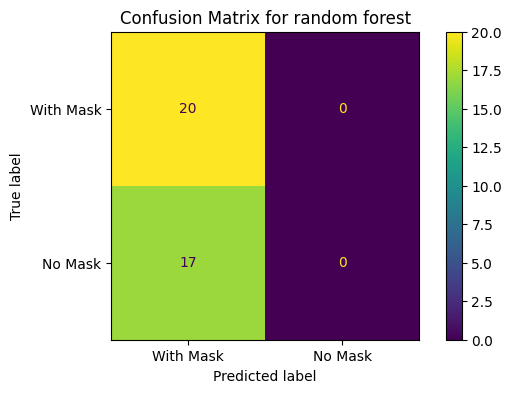


The validation accuracy of $54.1\%$ is simply the proportion of class $0$ in the two-class validation set. The validation balanced accuracy shows that the average of the recall score is $50\%$ meaning that for a balanced dataset we'll predict $1$ correct sample over $2$. 

Here parameters tuning is useless as whatever value we'll set the model will always predict the one class it has ever seen and is not capable of predicting something else. The confusion matrix is really explicit about that and we easily conclude that one "with mask" is ever predicted.

With a single class, we have no information about a boundary. For logistic regression, the unregularized MLE does not exist, since the intercept diverges. For SVM, the hinge loss is zero for infinitely many hyperplanes. There is then no solution and sklearn refuses to fit anything.


In [25]:
# TODO: answer Question 23, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...
display(Markdown(r"""We predict that the model will have an $100\%$ accuracy on this dataset as it should learn to always says $0$"""))

X_train_extra, X_val_extra, y_train_extra, y_val_extra = train_test_split(
    X_extra, labels_extra, test_size=0.2, random_state=SEED
)

rf_extra = RandomForestClassifier(n_estimators=30, random_state=SEED)
rf_extra.fit(X_train_extra, y_train_extra)

acc_extra_split = accuracy_score(y_val_extra, rf_extra.predict(X_val_extra))
print(f"Verified accuracy on extra-only split: {acc_extra_split:.3f}")

rf_extra.fit(X_extra, labels_extra)
y_pred_val_ex = rf_extra.predict(X_val)

acc_val = accuracy_score(y_val, y_pred_val_ex)
bacc_val = balanced_accuracy_score(y_val, y_pred_val_ex)

print(f"Validation (two-class) - Accuracy: {acc_val:.3f}")
print(f"Validation (two-class) - Balanced Accuracy: {bacc_val:.3f}")

plt.figure()
disp = ConfusionMatrixDisplay.from_estimator(rf_extra, X_val, y_val, display_labels=["With Mask", "No Mask"])
plt.title("Confusion Matrix for random forest")
plt.grid(False)
plt.show()

display(Markdown(r"""
The validation accuracy of $54.1\%$ is simply the proportion of class $0$ in the two-class validation set. The validation balanced accuracy shows that the average of the recall score is $50\%$ meaning that for a balanced dataset we'll predict $1$ correct sample over $2$. 

Here parameters tuning is useless as whatever value we'll set the model will always predict the one class it has ever seen and is not capable of predicting something else. The confusion matrix is really explicit about that and we easily conclude that one "with mask" is ever predicted.

With a single class, we have no information about a boundary. For logistic regression, the unregularized MLE does not exist, since the intercept diverges. For SVM, the hinge loss is zero for infinitely many hyperplanes. There is then no solution and sklearn refuses to fit anything.
"""))

### Question 24 — Combine the training data

Join **only the internal training portion** of `train.npz` with `extra`.
Keep validation untouched. Report counts and majority-class accuracy. Repeat the
Random Forest search from Question 19, selecting by balanced accuracy, and report
CV accuracy, CV balanced accuracy, and validation metrics. Explain why a high
ordinary accuracy on the combined distribution may be misleading. Do not report
resubstitution accuracy as generalization performance.

In [26]:
# TODO: answer Question 24, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...


# Combination of both training sets
X_train_combined = np.concatenate((X_train, X_extra), axis=0)
y_train_combined = np.concatenate((y_train, labels_extra), axis=0)

unique_comb, counts_comb = np.unique(y_train_combined, return_counts=True)
class_counts_comb = dict(zip(unique_comb, counts_comb))
majority_acc = counts_comb.max() / counts_comb.sum()
print(f"Combined training class counts: {class_counts_comb}")
print(f"Majority-class accuracy (combined): {majority_acc:.3f}")

# Repeat rf search
rf_comb = RandomForestClassifier(random_state=SEED)

# copy/pasted from Q19
param_grid_rf = {
    'n_estimators': [30, 100],
    'max_depth': [10, None],
    'criterion': ['gini', 'entropy']
}

grid_rf_comb = search(rf_comb, param_grid_rf, X_train_combined, y_train_combined)

best_idx_comb = grid_rf_comb.best_index_
cv_acc_comb = grid_rf_comb.cv_results_['mean_test_accuracy'][best_idx_comb]
cv_bacc_comb = grid_rf_comb.cv_results_['mean_test_balanced_accuracy'][best_idx_comb]

print(f"Selected parameters: {grid_rf_comb.best_params_}")
print(f"CV Accuracy: {cv_acc_comb:.3f}")
print(f"CV Balanced Accuracy: {cv_bacc_comb:.3f}")

# validation
best_model_comb = grid_rf_comb.best_estimator_
y_pred_val_comb = best_model_comb.predict(X_val)

val_acc_comb = accuracy_score(y_val, y_pred_val_comb)
val_bacc_comb = balanced_accuracy_score(y_val, y_pred_val_comb)

print(f"Validation - Accuracy: {val_acc_comb:.3f}")
print(f"Validation - Balanced Accuracy: {val_bacc_comb:.3f}")

display(Markdown(r"""
We see that we have a really high CV accuracy ($=98.7\%$), when comparing it with the majority-class accuracy ($=98.5\%$) we see that it is really close. And it shows that the model has probably learnt to always predict the same class. This intuition is reinforced by the CV balanced accuracy of $56.6\%$ which is really low. 

When looking at validation results we see that the balanced accuracy also felt to $64.7\%$ which is way lower than what we add in $Q19$ ($89.6\%$). 

By just adding $>4400$ images of class $0$ in our dataset, we skewed the data distribution and made our model loose any discriminative power.
"""))

Combined training class counts: {np.int64(0): np.int64(4538), np.int64(1): np.int64(69)}
Majority-class accuracy (combined): 0.985
Selected parameters: {'criterion': 'entropy', 'max_depth': None, 'n_estimators': 100}
CV Accuracy: 0.987
CV Balanced Accuracy: 0.566
Validation - Accuracy: 0.676
Validation - Balanced Accuracy: 0.647



We see that we have a really high CV accuracy ($=98.7\%$), when comparing it with the majority-class accuracy ($=98.5\%$) we see that it is really close. And it shows that the model has probably learnt to always predict the same class. This intuition is reinforced by the CV balanced accuracy of $56.6\%$ which is really low. 

When looking at validation results we see that the balanced accuracy also felt to $64.7\%$ which is way lower than what we add in $Q19$ ($89.6\%$). 

By just adding $>4400$ images of class $0$ in our dataset, we skewed the data distribution and made our model loose any discriminative power.


### Question 25 — Oversampling inside Random Forest cross-validation

Implement random oversampling of the minority class with replacement to match
the majority count. Repeat the Random Forest search using stratified folds:
oversample **each training fold only**, fit on it, and score the untouched validation
fold. After selection, oversample the full combined training set and refit.
Report CV and external validation metrics, including no-mask recall.

You may write a manual CV loop or a scikit-learn-compatible estimator whose `fit`
resamples and whose `predict` does not. Explain why oversampling before splitting
into CV folds leaks information and why duplicating images does not create new
independent observations. Keep a fixed resampling seed for comparable candidates.

In [27]:
# TODO: answer Question 25, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

param_grid = [
    {'n_estimators': n, 'max_depth': d, 'criterion': c}
    for n in [30, 100]
    for d in [10, None]
    for c in ['gini', 'entropy']
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rng = np.random.RandomState(SEED)

fold_data = []

for train_idx, val_idx in cv.split(X_train_combined, y_train_combined):
    X_fold_train = X_train_combined[train_idx]
    y_fold_train = y_train_combined[train_idx]

    X_fold_val = X_train_combined[val_idx]
    y_fold_val = y_train_combined[val_idx]

    class_0_idx = np.where(y_fold_train == 0)[0]
    class_1_idx = np.where(y_fold_train == 1)[0]

    n_majority = len(class_0_idx)
    resampled_class_1_idx = rng.choice(
        class_1_idx, size=n_majority, replace=True
    )

    X_fold_train_res = np.concatenate([
        X_fold_train[class_0_idx],
        X_fold_train[resampled_class_1_idx]
    ])
    y_fold_train_res = np.concatenate([
        y_fold_train[class_0_idx],
        y_fold_train[resampled_class_1_idx]
    ])

    fold_data.append((
        X_fold_train_res, y_fold_train_res,
        X_fold_val, y_fold_val
    ))

# Hyperparameter search
best_cv_score = -1
best_params = None

for params in param_grid:
    fold_scores = []

    for X_fold_train_res, y_fold_train_res, X_fold_val, y_fold_val in fold_data:
        rf = RandomForestClassifier(
            **params, random_state=SEED
        )
        rf.fit(X_fold_train_res, y_fold_train_res)

        y_pred = rf.predict(X_fold_val)
        fold_scores.append(
            balanced_accuracy_score(y_fold_val, y_pred)
        )

    mean_cv_score = np.mean(fold_scores)

    if mean_cv_score > best_cv_score:
        best_cv_score = mean_cv_score
        best_params = params

print(f"Selected parameters: {best_params}")
print(f"CV Balanced Accuracy: {best_cv_score:.3f}")

# Resample the complete training set for final training
class_0_full_idx = np.where(y_train_combined == 0)[0]
class_1_full_idx = np.where(y_train_combined == 1)[0]

resampled_class_1_full_idx = rng.choice(
    class_1_full_idx,
    size=len(class_0_full_idx),
    replace=True
)

X_train_combined_res = np.concatenate([
    X_train_combined[class_0_full_idx],
    X_train_combined[resampled_class_1_full_idx]
])
y_train_combined_res = np.concatenate([
    y_train_combined[class_0_full_idx],
    y_train_combined[resampled_class_1_full_idx]
])

final_rf = RandomForestClassifier(
    **best_params, random_state=SEED
)
final_rf.fit(X_train_combined_res, y_train_combined_res)

# Evaluate on the untouched validation set
y_val_pred = final_rf.predict(X_val)

val_acc = accuracy_score(y_val, y_val_pred)
val_bacc = balanced_accuracy_score(y_val, y_val_pred)
val_recall_1 = recall_score(y_val, y_val_pred, pos_label=1)

print(f"Validation - Accuracy: {val_acc:.3f}")
print(f"Validation - Balanced Accuracy: {val_bacc:.3f}")
print(f"Validation - No-Mask (Class 1) Recall: {val_recall_1:.3f}")

display(Markdown(r"""
We see that our internal oversampling method has forced the random forest to consider the minority class again as the balanced accuracy is now again up to $88.7\%$. The recall of class $1$ also went from $0$ to $82.4\%$ which proves that this class can now occupates some space again. 

CV balanced accuray of ($76.2\%$) is below the one of validation ($88.7\%$) because CV folds have extra class $0$ images, which come from a different distribution than validation. The two scores measure then measure different things.

If we first oversample before splitting the training set for CV, we could have some images that are both in the training set and the validation set. We absolutely don't want that as it would allow our model to "cheat", it has already seen the question we use for evaluating it and will thus over-perform. By splitting first, the validation fold remains completely untouched by the resampling and we can guarantee a proper separation of the data.

Random oversampling with replacement doesn't create new data points, it just artificially inflates the weights of the minority class $1$ data points. The model is now forced to learn to recognise them to avoid a big penalty. However as it contains no additional information (it's just a mathematical trick) we take the risk to make the model overfit this particular points. This could be why the CV method has selected a $\text{max\_depth} = 10$ instead of $\text{None}$. 
"""))

Selected parameters: {'n_estimators': 30, 'max_depth': 10, 'criterion': 'gini'}
CV Balanced Accuracy: 0.762
Validation - Accuracy: 0.892
Validation - Balanced Accuracy: 0.887
Validation - No-Mask (Class 1) Recall: 0.824



We see that our internal oversampling method has forced the random forest to consider the minority class again as the balanced accuracy is now again up to $88.7\%$. The recall of class $1$ also went from $0$ to $82.4\%$ which proves that this class can now occupates some space again. 

CV balanced accuray of ($76.2\%$) is below the one of validation ($88.7\%$) because CV folds have extra class $0$ images, which come from a different distribution than validation. The two scores measure then measure different things.

If we first oversample before splitting the training set for CV, we could have some images that are both in the training set and the validation set. We absolutely don't want that as it would allow our model to "cheat", it has already seen the question we use for evaluating it and will thus over-perform. By splitting first, the validation fold remains completely untouched by the resampling and we can guarantee a proper separation of the data.

Random oversampling with replacement doesn't create new data points, it just artificially inflates the weights of the minority class $1$ data points. The model is now forced to learn to recognise them to avoid a big penalty. However as it contains no additional information (it's just a mathematical trick) we take the risk to make the model overfit this particular points. This could be why the CV method has selected a $\text{max\_depth} = 10$ instead of $\text{None}$. 


### Question 26 — Oversampling with Logistic Regression

Repeat Question 25 using a scaled Logistic Regression with an $\ell_2$ penalty
and $C\in\{0.01,0.1,1,10,100\}$. Keep oversampling within each training fold,
including during hyperparameter selection. Compare with the oversampled forest
and the original-data Logistic Regression. Do not assume the ordering in advance.

In [28]:
# TODO: answer Question 26, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

c_values = [0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rng = np.random.RandomState(SEED)

# Precompute fold splits and resampled training data once
fold_data = []

for train_idx, val_idx in cv.split(X_train_combined, y_train_combined):
    X_fold_train = X_train_combined[train_idx]
    y_fold_train = y_train_combined[train_idx]

    X_fold_val = X_train_combined[val_idx]
    y_fold_val = y_train_combined[val_idx]

    class_0_idx = np.where(y_fold_train == 0)[0]
    class_1_idx = np.where(y_fold_train == 1)[0]

    resampled_class_1_idx = rng.choice(
        class_1_idx, size=len(class_0_idx), replace=True
    )

    X_fold_train_res = np.concatenate([
        X_fold_train[class_0_idx],
        X_fold_train[resampled_class_1_idx]
    ])
    y_fold_train_res = np.concatenate([
        y_fold_train[class_0_idx],
        y_fold_train[resampled_class_1_idx]
    ])

    # Fit scaler only on resampled training data
    scaler = StandardScaler()
    X_fold_train_res_scaled = scaler.fit_transform(X_fold_train_res)
    X_fold_val_scaled = scaler.transform(X_fold_val)

    fold_data.append((
        X_fold_train_res_scaled,
        y_fold_train_res,
        X_fold_val_scaled,
        y_fold_val
    ))

# Hyperparameter search: reuse identical resampled folds
best_cv_score_lr = -1
best_c = None

for c in c_values:
    fold_scores = []

    for (
        X_fold_train_res_scaled,
        y_fold_train_res,
        X_fold_val_scaled,
        y_fold_val
    ) in fold_data:

        lr = LogisticRegression(
            penalty='l2',
            C=c,
            solver='lbfgs',
            max_iter=2000,
            random_state=SEED
        )

        lr.fit(X_fold_train_res_scaled, y_fold_train_res)
        y_pred = lr.predict(X_fold_val_scaled)

        fold_scores.append(
            balanced_accuracy_score(y_fold_val, y_pred)
        )

    mean_cv_score = np.mean(fold_scores)

    if mean_cv_score > best_cv_score_lr:
        best_cv_score_lr = mean_cv_score
        best_c = c

print(f"Selected parameter: C = {best_c}")
print(f"CV Balanced Accuracy: {best_cv_score_lr:.3f}")

# Resample the complete training set for final training
class_0_full_idx = np.where(y_train_combined == 0)[0]
class_1_full_idx = np.where(y_train_combined == 1)[0]

resampled_class_1_full_idx = rng.choice(
    class_1_full_idx,
    size=len(class_0_full_idx),
    replace=True
)

X_train_combined_res = np.concatenate([
    X_train_combined[class_0_full_idx],
    X_train_combined[resampled_class_1_full_idx]
])
y_train_combined_res = np.concatenate([
    y_train_combined[class_0_full_idx],
    y_train_combined[resampled_class_1_full_idx]
])

# Fit final scaler on the resampled training data
final_scaler = StandardScaler()
X_train_combined_res_scaled = final_scaler.fit_transform(
    X_train_combined_res
)
X_val_scaled = final_scaler.transform(X_val)

# Train final logistic regression model
final_lr = LogisticRegression(
    penalty='l2',
    C=best_c,
    solver='lbfgs',
    max_iter=2000,
    random_state=SEED
)

final_lr.fit(X_train_combined_res_scaled, y_train_combined_res)

# Evaluate on untouched validation data
y_val_pred_lr = final_lr.predict(X_val_scaled)

val_acc_lr = accuracy_score(y_val, y_val_pred_lr)
val_bacc_lr = balanced_accuracy_score(y_val, y_val_pred_lr)
val_recall_1_lr = recall_score(y_val, y_val_pred_lr, pos_label=1)

print(f"Validation - Accuracy: {val_acc_lr:.3f}")
print(f"Validation - Balanced Accuracy: {val_bacc_lr:.3f}")
print(f"Validation - No-Mask (Class 1) Recall: {val_recall_1_lr:.3f}")

display(Markdown(r"""
We see that the oversamples logistic regression clearly is the best model I have trained until this point in the notebook. The balanced accuracy of $94.1\%$ as well as the class $1$ recall of $88.2\%$ are way better than their corresponding oversampled random forest metrics ($Q25$), respectively $88.7\%$ and $82.4\%$. As the logistic regression set an hyperplane it seems like it as a better generalization than the random forest in our case as the second ones tend to isolate specific area of the space. However we should not forget that the validation dataset are only 37 images so by just classifying correctly a few additional images can make a huge difference in the result even if it's still only 2 or 3 images.

It's also better than the $87.5\%$ balanced accuracy of the non-oversampled logistic regression of $Q17$. As we now have much more data to train on, the model could learn a better representation of the real-world variances. We just need to make sure we are not biasing the distribution in a particular direction due to class imbalance. This shows that highly biased external data is still valuable. 
"""))

Selected parameter: C = 10
CV Balanced Accuracy: 0.831
Validation - Accuracy: 0.946
Validation - Balanced Accuracy: 0.941
Validation - No-Mask (Class 1) Recall: 0.882



We see that the oversamples logistic regression clearly is the best model I have trained until this point in the notebook. The balanced accuracy of $94.1\%$ as well as the class $1$ recall of $88.2\%$ are way better than their corresponding oversampled random forest metrics ($Q25$), respectively $88.7\%$ and $82.4\%$. As the logistic regression set an hyperplane it seems like it as a better generalization than the random forest in our case as the second ones tend to isolate specific area of the space. However we should not forget that the validation dataset are only 37 images so by just classifying correctly a few additional images can make a huge difference in the result even if it's still only 2 or 3 images.

It's also better than the $87.5\%$ balanced accuracy of the non-oversampled logistic regression of $Q17$. As we now have much more data to train on, the model could learn a better representation of the real-world variances. We just need to make sure we are not biasing the distribution in a particular direction due to class imbalance. This shows that highly biased external data is still valuable. 


### Question 27 — Choose and justify a final model

Compare the three combined-data procedures from Questions 24–26 using their CV
balanced accuracy and unchanged validation metrics. Select a final procedure by
CV balanced accuracy; use validation for interpretation rather than repeatedly
tuning to it. Describe the method, selected parameters, and trade-offs.

For an optional extension, try at most one additional clearly specified procedure
(for example class weighting) under exactly the same CV protocol. A larger search
or higher score is not required for full credit. Do not access the final test data.

In [29]:
# TODO: answer Question 27, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

display(Markdown(r"""
| Procedure   | Method                                      | CV Balanced Acc | Validation Balanced Acc |
|-------------|---------------------------------------------|-----------------|-------------------------|
| Question 24 | Random Forest (Naive Combined)              | 0.566           | 0.647                   |
| Question 25 | Random Forest (Interior Oversampling)       | 0.762           | 0.887                   |
| Question 26 | Logistic Regression (Interior Oversampling) | 0.831           | 0.941                   |

Based strictly on the cross-validation balanced accuracy, the oversampled logistic regression from $Q26$ must be the selected final model. The good news is that with a $94.1\%$ of validation balanced accuracy this model also performed best on the validation split.

The method to built it was the following:
1. Extract the flattened feature vectors
2. Cross-validate (5-fold stratified) the logistic regression model ($\ell_2$) to select $C=10$ by applying random oversampling and `StandardScaler` inside the training folds
3. Oversample the minority class across the full combined training set to balance the classes
4. Fit the final `StandardScaler` and $\ell_2$ logistic regression ($C=10$) on the entire oversampled dataset.

Trade-offs:
- **+** $\rightarrow$ By including the big amounts of data from the extra dataset and applying aversampling, we allowed the model to learn a generalized boundary. The $\ell_2$ regularization helps smoothings out the separating hyperplane and prevents localized overfitting that penalized the random forest accuracy. 
- **-** $\rightarrow$ By choosing a linear model we are blind to other data dynamics as we can only separate them by an hyperplane. If the true function is non-linear, it means that we'll never be able to teach exactly hwo to separate the classes to our model, even if we have an infinite amount of data

Another problem is that if we have a really huge dataset one might not want to do the oversampling method as it's computationally and memory expensive by definition (artificially enlarge dataset). To avoid it we could apply a class weighting methos as suggested. Now instead of duplicating minority samples, we directly modify the loss functions by setting the penalty of each misclassification inversely proportional to its class frequencies. By doing so a wrongly classified minority sample will have much more weights than a wrongly classified majority sample.

"""))

pipe_cw = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l2', class_weight='balanced', 
                       solver='lbfgs', max_iter=2000, random_state=SEED)
)

param_grid_cw = {
    'logisticregression__C': [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

grid_cw = GridSearchCV(pipe_cw, param_grid_cw, scoring='balanced_accuracy', 
                       cv=cv, n_jobs=1).fit(X_train_combined, y_train_combined)

best_cw_model = grid_cw.best_estimator_

print(f"Selected parameters (Class Weighting): {grid_cw.best_params_}")
print(f"CV Balanced Accuracy: {grid_cw.best_score_:.3f}")

y_val_pred_cw = best_cw_model.predict(X_val)

print(f"Validation - Accuracy: {accuracy_score(y_val, y_val_pred_cw):.3f}")
print(f"Validation - Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_pred_cw):.3f}")
print(f"Validation - No-Mask Recall: {recall_score(y_val, y_val_pred_cw, pos_label=1):.3f}")

display(Markdown(r"""
| Method                                      | CV Balanced Acc | Validation Balanced Acc |
|---------------------------------------------|-----------------|-------------------------|
|  Logistic Regression (Interior Oversampling)| 0.831           | 0.941                   |
|  Logistic egression (Class Weighting)       | 0.844           | 0.971                   |

We observe that the class weighting procedure outperformed manual oversampling in both CV balanced accuracy and validation balanced accuracy. So we select it for our final model.

As we have a really week minority, we must oversamples a lot to balance with the other class. As we are choosing our samples randomly with replacements the minority class could become bias, for example a point could be choosen $100$ times where another could only be selected a few times. This creates imbalancies inside the imbalanced class, so we are introducing some noise. Class weighting corrects that problem by setting an equal weight to all minority samples.

We see that the selected hyperparameters was $C=10$ (weak regularization) with oversampling but it's only $0.01$ (strong regularization) with class weighting. The strong regularization makes a much smoother hyperplane that likely reduce overfitting and improve generalization.
We also see that the $C=0.01$ is on the limit of our paramater grid, however the instructions explicitly says that *"A larger search or higher score is not required"* so I'll keep this parameter grid. 

The final selected method is then:
1. Extract the flattened feature vectors
2. Cross-validate (5-fold stratified) the logistic regression model ($\ell_2$) to select $C=0.01$ by applying class weighting and `StandardScaler` inside the training folds
4. Fit the final `StandardScaler` and $\ell_2$ class weighting logistic regression ($C=0.01$) on the entire dataset.
"""))


| Procedure   | Method                                      | CV Balanced Acc | Validation Balanced Acc |
|-------------|---------------------------------------------|-----------------|-------------------------|
| Question 24 | Random Forest (Naive Combined)              | 0.566           | 0.647                   |
| Question 25 | Random Forest (Interior Oversampling)       | 0.762           | 0.887                   |
| Question 26 | Logistic Regression (Interior Oversampling) | 0.831           | 0.941                   |

Based strictly on the cross-validation balanced accuracy, the oversampled logistic regression from $Q26$ must be the selected final model. The good news is that with a $94.1\%$ of validation balanced accuracy this model also performed best on the validation split.

The method to built it was the following:
1. Extract the flattened feature vectors
2. Cross-validate (5-fold stratified) the logistic regression model ($\ell_2$) to select $C=10$ by applying random oversampling and `StandardScaler` inside the training folds
3. Oversample the minority class across the full combined training set to balance the classes
4. Fit the final `StandardScaler` and $\ell_2$ logistic regression ($C=10$) on the entire oversampled dataset.

Trade-offs:
- **+** $\rightarrow$ By including the big amounts of data from the extra dataset and applying aversampling, we allowed the model to learn a generalized boundary. The $\ell_2$ regularization helps smoothings out the separating hyperplane and prevents localized overfitting that penalized the random forest accuracy. 
- **-** $\rightarrow$ By choosing a linear model we are blind to other data dynamics as we can only separate them by an hyperplane. If the true function is non-linear, it means that we'll never be able to teach exactly hwo to separate the classes to our model, even if we have an infinite amount of data

Another problem is that if we have a really huge dataset one might not want to do the oversampling method as it's computationally and memory expensive by definition (artificially enlarge dataset). To avoid it we could apply a class weighting methos as suggested. Now instead of duplicating minority samples, we directly modify the loss functions by setting the penalty of each misclassification inversely proportional to its class frequencies. By doing so a wrongly classified minority sample will have much more weights than a wrongly classified majority sample.



Selected parameters (Class Weighting): {'logisticregression__C': 0.01}
CV Balanced Accuracy: 0.844
Validation - Accuracy: 0.973
Validation - Balanced Accuracy: 0.971
Validation - No-Mask Recall: 0.941



| Method                                      | CV Balanced Acc | Validation Balanced Acc |
|---------------------------------------------|-----------------|-------------------------|
|  Logistic Regression (Interior Oversampling)| 0.831           | 0.941                   |
|  Logistic egression (Class Weighting)       | 0.844           | 0.971                   |

We observe that the class weighting procedure outperformed manual oversampling in both CV balanced accuracy and validation balanced accuracy. So we select it for our final model.

As we have a really week minority, we must oversamples a lot to balance with the other class. As we are choosing our samples randomly with replacements the minority class could become bias, for example a point could be choosen $100$ times where another could only be selected a few times. This creates imbalancies inside the imbalanced class, so we are introducing some noise. Class weighting corrects that problem by setting an equal weight to all minority samples.

We see that the selected hyperparameters was $C=10$ (weak regularization) with oversampling but it's only $0.01$ (strong regularization) with class weighting. The strong regularization makes a much smoother hyperplane that likely reduce overfitting and improve generalization.
We also see that the $C=0.01$ is on the limit of our paramater grid, however the instructions explicitly says that *"A larger search or higher score is not required"* so I'll keep this parameter grid. 

The final selected method is then:
1. Extract the flattened feature vectors
2. Cross-validate (5-fold stratified) the logistic regression model ($\ell_2$) to select $C=0.01$ by applying class weighting and `StandardScaler` inside the training folds
4. Fit the final `StandardScaler` and $\ell_2$ class weighting logistic regression ($C=0.01$) on the entire dataset.


### Question 28 — Error costs (optional)

Suppose missing a person without a mask is more costly than falsely flagging a
masked person. Explain how class weights or a decision threshold could reflect
this. As a small diagnostic, compare weights `{0: 1, 1: 1}` and `{0: 1, 1: 3}` in
a Random Forest using the parameters from Question 24. Report both class recalls
on validation. Do not claim that a weight of 3 guarantees a specified recall or
implements a calibrated cost-optimal policy. Keep Question 27's final selection
fixed for the standard benchmark in Question 29.

In [30]:
# TODO: answer Question 28, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

# from Q24
rf_params = {**grid_rf_comb.best_params_, "random_state": SEED}

# 1:1
rf_w1 = RandomForestClassifier(**rf_params, class_weight={0: 1, 1: 1})
rf_w1.fit(X_train_combined, y_train_combined)
y_pred_w1 = rf_w1.predict(X_val)

# 1:3
rf_w3 = RandomForestClassifier(**rf_params, class_weight={0: 1, 1: 3})
rf_w3.fit(X_train_combined, y_train_combined)
y_pred_w3 = rf_w3.predict(X_val)

print("--- Weights {0: 1, 1: 1} ---")
print(f"Mask (Class 0) Recall: {recall_score(y_val, y_pred_w1, pos_label=0):.3f}")
print(f"No-Mask (Class 1) Recall: {recall_score(y_val, y_pred_w1, pos_label=1):.3f}")

print("\n--- Weights {0: 1, 1: 3} ---")
print(f"Mask (Class 0) Recall: {recall_score(y_val, y_pred_w3, pos_label=0):.3f}")
print(f"No-Mask (Class 1) Recall: {recall_score(y_val, y_pred_w3, pos_label=1):.3f}")

display(Markdown(r"""
Class weights multiply the loss of class-1 errors, therefore missing a no-mask person costs more. We arificially push the model to miss fewer points, but it will also likely increase the false positive. Moreover we cannot guarantee a given recall. 
"""))

--- Weights {0: 1, 1: 1} ---
Mask (Class 0) Recall: 1.000
No-Mask (Class 1) Recall: 0.294

--- Weights {0: 1, 1: 3} ---
Mask (Class 0) Recall: 1.000
No-Mask (Class 1) Recall: 0.412



Class weights multiply the loss of class-1 errors, therefore missing a no-mask person costs more. We arificially push the model to miss fewer points, but it will also likely increase the false positive. Moreover we cannot guarantee a given recall. 


### Question 29 — Freeze, refit, and evaluate once

Freeze the procedure and hyperparameters selected in Question 27. Refit on all of
`train.npz` plus `extra.npz`, now including the development validation observations.
Use resampling only if it belongs to your selected procedure. Then, for the first
time, evaluate on `test.npz` using `evaluate` and display a confusion matrix.

Compare final test metrics with your development estimates. Explain why scores
can change without an implementation error, why duplication did not increase the
number of independent no-mask examples, and why you must not select a replacement
model using this final test result. State important limitations of this experiment.

Final test metrics: {'accuracy': 0.8666092943201377, 'balanced_accuracy': 0.8675400549867274, 'recall_no_mask': 0.7593856655290102}

Final Model Evaluation on Test Set:
  accuracy = 0.867
  balanced_accuracy = 0.868
  recall_no_mask = 0.759


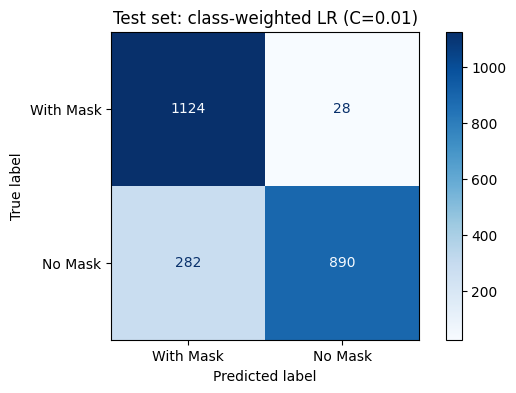


We see that the final score (balanced accuracy of $86.8\%$) is lower than the one we had in validation. This in part due to the fact that the validation set had only 37 samples, this is subject to statistical variance as switching one image shifts accuracy by $2.7\%$.

Also the final test dataset is a distinct, previously unseen sample from the underlying distribution. Even if we had build a perfect unbiased model our final score would have experienced fluctuations across different finite samples. This is simply due to the natural variance in the data distribution and to the fact that two different dataset will gives two different results.

We see on the confusion matrix that we still miss a lot of the "no-mask" images. Even tho we took care to weight our loss function we still have a small amount of training data. If an area of the dataspace was supposed to be strongly filled with this class but we have no training data from there, our model cannot *guess* that it should be a "no-mask" image and thus assign it to the other class. To correct it we would need more training "no-mask" images.

The purpose of this final test set is to expose our model to unseen-real world data that it has never seen before in order to assess it's performance in real condition. If we would have the terrible idea to adjust our model parameters to improve the final score, we are then optimizing the model for the test set. Some informations from the test set are now into the training process and the test set basically becomes a seconde validation dataset. We therefore cannot reuse it for a later evaluation and would need to gather a complete fresh new test set. So it's why the test set must never be used for further tuning.

Now the main limitations of this second exercise homework experiment is that: 
- Flattening an image into a 1D array is obviously a questionable choice as we destroy any spatial information (edges, shapes, etc), we add to that the $128\times 128\rightarrow 32\times 32$ downsampling and we can only end up with a poorer representation of the image.
- The validation set is small ($37$ images) it leads to high variance in the results. A single image can shift the accuracy by $2.7\%$.
- Even without flattening the image we'll still probably encounter a problem with the number of training class $0$ images
- The true dynamic of the question "Is that person masked or not ?" is probably harder than a simple linear hyperplane due to the diversity of the image space (environment/background, photo angle, skin color, ...). Based on my experience with this dataset (I looked at all \textbf{training} images), all the images we have appear to be well-framed, with the face as the main subject and the individuals facing forward.


In [31]:
# TODO: answer Question 29, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

images_train, labels_train = load_file("train")
images_extra, labels_extra = load_file("extra")

X_train_full = image_features(images_train)
X_extra = image_features(images_extra)

X_combined = np.concatenate((X_train_full, X_extra), axis=0)
y_combined = np.concatenate((labels_train, labels_extra), axis=0)

final_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty='l2', 
        C=0.01, 
        class_weight='balanced', 
        solver='lbfgs', 
        max_iter=2000, 
        random_state=SEED
    )
)

final_model = final_pipeline.fit(X_combined, y_combined)

results = evaluate(final_model)

print("\nFinal Model Evaluation on Test Set:")
for metric, value in results.items():
    print(f"  {metric} = {value:.3f}")

images_test, labels_test = load_file("test")

y_pred_test = final_model.predict(image_features(images_test))

fig, ax = plt.subplots()
ax.grid(False)

ConfusionMatrixDisplay.from_predictions(labels_test, y_pred_test,
        display_labels=["With Mask", "No Mask"], cmap="Blues", ax=ax)
ax.set_title("Test set: class-weighted LR (C=0.01)")
plt.show()

display(Markdown(r"""
We see that the final score (balanced accuracy of $86.8\%$) is lower than the one we had in validation. This in part due to the fact that the validation set had only 37 samples, this is subject to statistical variance as switching one image shifts accuracy by $2.7\%$.

Also the final test dataset is a distinct, previously unseen sample from the underlying distribution. Even if we had build a perfect unbiased model our final score would have experienced fluctuations across different finite samples. This is simply due to the natural variance in the data distribution and to the fact that two different dataset will gives two different results.

We see on the confusion matrix that we still miss a lot of the "no-mask" images. Even tho we took care to weight our loss function we still have a small amount of training data. If an area of the dataspace was supposed to be strongly filled with this class but we have no training data from there, our model cannot *guess* that it should be a "no-mask" image and thus assign it to the other class. To correct it we would need more training "no-mask" images.

The purpose of this final test set is to expose our model to unseen-real world data that it has never seen before in order to assess it's performance in real condition. If we would have the terrible idea to adjust our model parameters to improve the final score, we are then optimizing the model for the test set. Some informations from the test set are now into the training process and the test set basically becomes a seconde validation dataset. We therefore cannot reuse it for a later evaluation and would need to gather a complete fresh new test set. So it's why the test set must never be used for further tuning.

Now the main limitations of this second exercise homework experiment is that: 
- Flattening an image into a 1D array is obviously a questionable choice as we destroy any spatial information (edges, shapes, etc), we add to that the $128\times 128\rightarrow 32\times 32$ downsampling and we can only end up with a poorer representation of the image.
- The validation set is small ($37$ images) it leads to high variance in the results. A single image can shift the accuracy by $2.7\%$.
- Even without flattening the image we'll still probably encounter a problem with the number of training class $0$ images
- The true dynamic of the question "Is that person masked or not ?" is probably harder than a simple linear hyperplane due to the diversity of the image space (environment/background, photo angle, skin color, ...). Based on my experience with this dataset (I looked at all \textbf{training} images), all the images we have appear to be well-framed, with the face as the main subject and the individuals facing forward.
"""))

Before submission, restart the kernel and run your notebook in order. Check that
every required question has an explanation, every figure is labelled, and your
reported conclusions match your actual outputs. Include a short account of any
AI assistance and the checks you performed. Keep the final-test result as the
assessment of your frozen procedure rather than using it for another tuning cycle.

### AI Assistance

I acknowledge that I used LLMs (Anthropic Claude and Google Gemini) during this assessment.

I used it to:
- Write, refine, and debug my code, as well as generate plots.
- Get feedback on my answers to ensure they were relevant and not off-topic.
- Guide me through the hardest problems and answer my understanding questions.
- Convert handwritten equations from my ipad into compatible latex/markdown format.

After 3 days of work I can state that I take the full responsibility for the whole content of this submission.

Eloi Dutruy 

SCIPER 355726